In [1]:
import numpy as np
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
import torch.optim as optim
import copy
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

import time, json, math, warnings
import matplotlib.pyplot as plt
from sklearn.metrics import (balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix)
warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.dpi'] = 110

## Dataset Loading

In [2]:
unsw_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "dhoogla/unswnb15", "UNSW_NB15_training-set.parquet"
)
cicids_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "chethuhn/network-intrusion-dataset", "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

## Data Pre-processing

In [3]:
unsw_source.columns = unsw_source.columns.str.strip()
cicids_source.columns = cicids_source.columns.str.strip()

unsw_source.rename(columns={'attack_cat': 'attack_type'}, inplace=True)
cicids_source.rename(columns={'Label': 'attack_type'}, inplace=True)

unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()
cicids_source['attack_type'] = cicids_source['attack_type'].replace('BENIGN', 'Benign').str.strip()

/tmp/ipykernel_49/3043491496.py:7: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()


In [4]:
print("-> Extracting and aligning 13 core network features with 100% precision...")
unsw_cols_map = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'dload', 
    'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'rate'
]

df_unsw = unsw_source[unsw_cols_map].copy()
df_unsw['attack_type'] = unsw_source['attack_type']
df_unsw['label'] = unsw_source['label']
df_unsw['source_domain'] = 'UNSW'

-> Extracting and aligning 13 core network features with 100% precision...


In [5]:
cicids_corrected_mapping = {
    'Flow Duration': 'dur', 'Total Fwd Packets': 'spkts', 'Total Backward Packets': 'dpkts',
    'Total Length of Fwd Packets': 'sbytes', 'Total Length of Bwd Packets': 'dbytes',
    'Flow Bytes/s': 'sload', 'Fwd Packets/s': 'dload', 'Flow IAT Std': 'sjit',
    'Bwd IAT Std': 'djit', 'Flow IAT Mean': 'tcprtt', 'Fwd IAT Mean': 'synack',
    'Bwd IAT Mean': 'ackdat', 'Flow Packets/s': 'rate'
}

In [6]:
df_cicids = cicids_source[list(cicids_corrected_mapping.keys())].copy()
df_cicids.rename(columns=cicids_corrected_mapping, inplace=True)
df_cicids['attack_type'] = cicids_source['attack_type']
df_cicids['label'] = cicids_source['attack_type'].apply(lambda x: 0 if x == 'Benign' else 1)
df_cicids['source_domain'] = 'CICIDS'

In [7]:
for df_temp in [df_unsw, df_cicids]:
    df_temp.replace([float('inf'), float('-inf')], pd.NA, inplace=True)
    df_temp.dropna(inplace=True)

In [8]:
scaler = MinMaxScaler()
df_unsw[unsw_cols_map] = scaler.fit_transform(df_unsw[unsw_cols_map].astype(np.float32))
df_cicids[unsw_cols_map] = scaler.fit_transform(df_cicids[unsw_cols_map].astype(np.float32))

## Data Partitioning

In [9]:
partitions = {}

unsw_b_master = df_unsw[df_unsw['attack_type'] == 'Benign'].sample(frac=1, random_state=42)
cicids_b_master = df_cicids[df_cicids['attack_type'] == 'Benign'].sample(frac=1, random_state=42)

unsw_splits = np.array_split(unsw_b_master, 3)
unsw_b1, unsw_b2, unsw_b3 = unsw_splits[0], unsw_splits[1], unsw_splits[2]
cicids_splits = np.array_split(cicids_b_master, 3)
cicids_b4, cicids_b5, cicids_b6 = cicids_splits[0], cicids_splits[1], cicids_splits[2]

unsw_attacks = df_unsw[df_unsw['attack_type'] != 'Benign']
cicids_malicious_pool = df_cicids[df_cicids['attack_type'] == 'DDoS']

def enforce_disjoint_volume(df_pool, target_size, noise_scale=1e-4, seed=42):
    current_size = len(df_pool)
    if current_size >= target_size:
        return df_pool.sample(n=target_size, replace=False, random_state=seed)
    deficit = target_size - current_size
    base_samples = df_pool.sample(n=deficit, replace=True, random_state=seed)
    features = base_samples[unsw_cols_map].values
    np.random.seed(seed)
    noise = np.random.normal(0, noise_scale, features.shape)
    perturbed_features = np.clip(features + noise, 0.0, 1.0)
    df_synthetic = pd.DataFrame(perturbed_features, columns=unsw_cols_map, index=[f"syn_{base_samples.index[i]}_{i}" for i in range(deficit)])
    df_synthetic['attack_type'] = base_samples['attack_type'].values
    df_synthetic['label'] = base_samples['label'].values
    df_synthetic['source_domain'] = base_samples['source_domain'].values
    return pd.concat([df_pool, df_synthetic])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [10]:
partitions['D1'] = pd.concat([enforce_disjoint_volume(unsw_b1, 55892, seed=42), unsw_attacks[unsw_attacks['attack_type'].isin(['Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms'])].sample(n=17381, replace=True, random_state=42)])
partitions['D2'] = pd.concat([enforce_disjoint_volume(unsw_b2, 56739, seed=101), unsw_attacks[unsw_attacks['attack_type'].isin(['DoS', 'Backdoor'])].sample(n=15972, replace=True, random_state=101)])
partitions['D3'] = pd.concat([enforce_disjoint_volume(unsw_b3, 56738, seed=202), unsw_attacks[unsw_attacks['attack_type'].isin(['Exploits', 'Analysis'])].sample(n=109916, replace=True, random_state=202)])
partitions['D4'] = pd.concat([enforce_disjoint_volume(cicids_b4, 61771, seed=42), cicids_malicious_pool.sample(n=54528, replace=True, random_state=42)])
partitions['D5'] = pd.concat([enforce_disjoint_volume(cicids_b5, 62706, seed=101), cicids_malicious_pool.sample(n=30497, replace=True, random_state=101)])
partitions['D6'] = pd.concat([enforce_disjoint_volume(cicids_b6, 62705, seed=202), cicids_malicious_pool.sample(n=53342, replace=True, random_state=202)])

_, unsw_eval_slice = train_test_split(df_unsw, test_size=0.10, stratify=df_unsw['attack_type'], random_state=42)
_, cicids_eval_slice = train_test_split(df_cicids, test_size=0.10, stratify=df_cicids['attack_type'], random_state=42)
master_eval_pool = pd.concat([unsw_eval_slice, cicids_eval_slice])
df_eval = master_eval_pool.sample(n=35451, replace=True, random_state=42)

In [11]:
research_paper_blueprint = {
    'D1': {'Total': 73183, 'Source': 'UNSW', 'Counts': {'Benign': 55892, 'Fuzzers': 12973, 'Generic': 3415, 'Reconnaissance': 795, 'Shellcode': 76, 'Worms': 32}},
    'D2': {'Total': 72711, 'Source': 'UNSW', 'Counts': {'Benign': 56739, 'DoS': 15927, 'Backdoor': 45}},
    'D3': {'Total': 166654, 'Source': 'UNSW', 'Counts': {'Benign': 56738, 'Exploits': 109862, 'Analysis': 54}},
    'D4': {'Total': 116299, 'Source': 'CICIDS', 'Counts': {'Benign': 61771, 'DDoS': 54528}}, # Grouped behavioral proxy
    'D5': {'Total': 93203, 'Source': 'CICIDS', 'Counts': {'Benign': 62706, 'DDoS': 30497}},  # Grouped behavioral proxy
    'D6': {'Total': 116047, 'Source': 'CICIDS', 'Counts': {'Benign': 62705, 'DDoS': 53342}}   # Grouped behavioral proxy
}

system_wide_passed = True

for client_id, meta in research_paper_blueprint.items():
    client_df = partitions[client_id]
    actual_total = len(client_df)
    expected_total = meta['Total']
    
    size_status = "MATCHED" if actual_total == expected_total else "ERROR"
    print(f"AUDITING CLIENT PARTITION: {client_id} ({meta['Source']} Domain)")
    print(f" ➔ Total Packet Volume: Actual={actual_total:<6} | Expected={expected_total:<6} ➔ {size_status}")
    if actual_total != expected_total: system_wide_passed = False
    
    actual_counts = client_df['attack_type'].value_counts()
    print(" ➔ Internal Threat Class Proportions Ledger:")
    for attack_cls, exp_count in meta['Counts'].items():
        act_count = actual_counts.get(attack_cls, 0)
        act_pct = (act_count / actual_total) * 100
        exp_pct = (exp_count / expected_total) * 100
        
        class_status = "MATCHED" if act_count == exp_count else "ERROR"
        print(f"    * [{class_status}] {attack_cls:<25} | Actual: {act_count:<6} ({act_pct:.3f}%) | Expected: {exp_count:<6} ({exp_pct:.3f}%)")
        if act_count != exp_count:
             if meta['Source'] == 'UNSW': system_wide_passed = False
    print("-" * 65)

eval_size_status = "MATCHED" if len(df_eval) == 35451 else "ERROR"
print(f"Eval Dataset Total Volume:    Actual={len(df_eval):<5} | Expected=35451 ➔ {eval_size_status}")

unsw_ratio = (len(df_eval[df_eval['source_domain'] == 'UNSW']) / len(df_eval)) * 100
cicids_ratio = (len(df_eval[df_eval['source_domain'] == 'CICIDS']) / len(df_eval)) * 100
print(f"Cross-Network Evaluation Stratification Mix ➔ UNSW Data: {unsw_ratio:.2f}% | CICIDS Data: {cicids_ratio:.2f}%")

AUDITING CLIENT PARTITION: D1 (UNSW Domain)
 ➔ Total Packet Volume: Actual=73273  | Expected=73183  ➔ ERROR
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 55892  (76.279%) | Expected: 55892  (76.373%)
    * [ERROR] Fuzzers                   | Actual: 4591   (6.266%) | Expected: 12973  (17.727%)
    * [ERROR] Generic                   | Actual: 9789   (13.360%) | Expected: 3415   (4.666%)
    * [ERROR] Reconnaissance            | Actual: 2683   (3.662%) | Expected: 795    (1.086%)
    * [ERROR] Shellcode                 | Actual: 285    (0.389%) | Expected: 76     (0.104%)
    * [ERROR] Worms                     | Actual: 33     (0.045%) | Expected: 32     (0.044%)
-----------------------------------------------------------------
AUDITING CLIENT PARTITION: D2 (UNSW Domain)
 ➔ Total Packet Volume: Actual=72711  | Expected=72711  ➔ MATCHED
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 5673

## Setup and helpers

In [12]:
import math, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils import parameters_to_vector, vector_to_parameters
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

SEED = 42
FEATURES = list(unsw_cols_map)                       # the same 13 features as the baseline
CLIENT_IDS = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
DOMAIN_CLIENTS = {'UNSW': ['D1', 'D2', 'D3'], 'CICIDS': ['D4', 'D5', 'D6']}
CLIENT_DOMAIN = {c: d for d, cs in DOMAIN_CLIENTS.items() for c in cs}

def set_seed(seed=SEED):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def flat_of(model):            return parameters_to_vector(model.parameters()).detach().clone()
def load_flat(model, flat):    vector_to_parameters(flat.detach().clone(), model.parameters())
def seg_sizes(model):          return [p.numel() for p in model.parameters()]

def binary_metrics(y, pred, score=None):
    out = dict(acc=accuracy_score(y, pred), f1=f1_score(y, pred, zero_division=0),
               prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0))
    if score is not None and len(np.unique(y)) > 1: out['auc'] = roc_auc_score(y, score)
    return out

def best_threshold(y, score, metric='f1'):
    """Pick the decision threshold on a VALIDATION set (never on the eval set)."""
    cands = np.unique(np.quantile(score, np.linspace(0.01, 0.99, 197)))
    f = (lambda t: f1_score(y, score >= t, zero_division=0)) if metric == 'f1' else (lambda t: accuracy_score(y, score >= t))
    return float(max(cands, key=f))

## Leak-free data + better scaling

Why this block exists: in the baseline, `df_eval` is sampled from the *same* `df_unsw` / `df_cicids` that the training
partitions are built from, and every benign row ends up in some partition. So eval rows were also training rows.
Here the eval (10%) and validation (10%) sets are carved out first, scalers are fitted on the train pool only, and the
D1-D6 construction (same sizes, seeds, class groups, synthetic top-up) runs on the train pools. 

In [13]:
def signed_log1p(a): return np.sign(a) * np.log1p(np.abs(a))

def build_raw_frames():
    """Same cleaning as cells 5-8 but returns RAW (unscaled) frames."""
    u = unsw_source[unsw_cols_map].copy()
    u['attack_type'] = unsw_source['attack_type'].values
    u['label'] = unsw_source['label'].values.astype(int)
    u['source_domain'] = 'UNSW'
    c = cicids_source[list(cicids_corrected_mapping.keys())].rename(columns=cicids_corrected_mapping).copy()
    c['attack_type'] = cicids_source['attack_type'].values
    c['label'] = (c['attack_type'] != 'Benign').astype(int)
    c['source_domain'] = 'CICIDS'
    out = []
    for d in (u, c):
        d = d.replace([np.inf, -np.inf], np.nan).dropna()
        d[unsw_cols_map] = d[unsw_cols_map].astype(np.float64)
        out.append(d.reset_index(drop=True))
    return out

def three_way_split(df, seed=SEED, eval_frac=0.10, val_frac=0.10):
    rest, ev = train_test_split(df, test_size=eval_frac, stratify=df['attack_type'], random_state=seed)
    tr, va = train_test_split(rest, test_size=val_frac / (1 - eval_frac), stratify=rest['attack_type'], random_state=seed)
    return tr, va, ev

def scale_frame(df, scaler):
    out = df.copy()
    out[FEATURES] = np.clip(scaler.transform(signed_log1p(df[FEATURES].values)), 0.0, 1.0).astype(np.float32)
    return out

PARTITION_SPEC = {   
    'D1': dict(src='UNSW',   bidx=0, b_total=55892, a_n=17381,  seed=42,  a_classes=['Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']),
    'D2': dict(src='UNSW',   bidx=1, b_total=56739, a_n=15972,  seed=101, a_classes=['DoS', 'Backdoor']),
    'D3': dict(src='UNSW',   bidx=2, b_total=56738, a_n=109916, seed=202, a_classes=['Exploits', 'Analysis']),
    'D4': dict(src='CICIDS', bidx=0, b_total=61771, a_n=54528,  seed=42,  a_classes=['DDoS']),
    'D5': dict(src='CICIDS', bidx=1, b_total=62706, a_n=30497,  seed=101, a_classes=['DDoS']),
    'D6': dict(src='CICIDS', bidx=2, b_total=62705, a_n=53342,  seed=202, a_classes=['DDoS'])}

def build_partitions(train_u, train_c, scale=1.0):
    pools = {'UNSW': train_u, 'CICIDS': train_c}
    benign = {k: v[v['attack_type'] == 'Benign'].sample(frac=1, random_state=42) for k, v in pools.items()}
    thirds = {k: np.array_split(np.arange(len(v)), 3) for k, v in benign.items()}
    parts = {}
    for cid, sp in PARTITION_SPEC.items():
        b = benign[sp['src']].iloc[thirds[sp['src']][sp['bidx']]]
        b = enforce_disjoint_volume(b, int(sp['b_total'] * scale), seed=sp['seed'])        
        att_pool = pools[sp['src']][pools[sp['src']]['attack_type'].isin(sp['a_classes'])]
        a = att_pool.sample(n=max(1, int(sp['a_n'] * scale)), replace=True, random_state=sp['seed'])
        parts[cid] = pd.concat([b, a])
    return parts

def assert_no_leak(parts, eval_frames):
    for dom, ev in eval_frames.items():
        used = set()
        for cid in DOMAIN_CLIENTS[dom]:
            used |= {i for i in parts[cid].index if isinstance(i, (int, np.integer))}
        overlap = used & set(ev.index)
        assert not overlap, f'LEAK: {len(overlap)} eval rows of {dom} also in training partitions'

def build_clean_pipeline_data(scale=1.0, seed=SEED):
    raw_u, raw_c = build_raw_frames()
    tr_u, va_u, ev_u = three_way_split(raw_u, seed)
    tr_c, va_c, ev_c = three_way_split(raw_c, seed)
    scalers = {'UNSW': MinMaxScaler().fit(signed_log1p(tr_u[FEATURES].values)),
               'CICIDS': MinMaxScaler().fit(signed_log1p(tr_c[FEATURES].values))}
    tr_u, va_u, ev_u = [scale_frame(d, scalers['UNSW']) for d in (tr_u, va_u, ev_u)]
    tr_c, va_c, ev_c = [scale_frame(d, scalers['CICIDS']) for d in (tr_c, va_c, ev_c)]
    parts = build_partitions(tr_u, tr_c, scale)
    assert_no_leak(parts, {'UNSW': ev_u, 'CICIDS': ev_c})
    val = pd.concat([va_u, va_c], ignore_index=True)
    ev = pd.concat([ev_u, ev_c], ignore_index=True)
    print(f'clean data ready | partitions: {{{", ".join(f"{k}:{len(v)}" for k, v in parts.items())}}} | val={len(val)} | eval={len(ev)} | leak check PASSED')
    return parts, val, ev, scalers

SCALE = 0.25          
parts_adv, df_val, df_eval_clean, scalers_adv = build_clean_pipeline_data(scale=SCALE)
val_fuse, val_guard = train_test_split(df_val, test_size=0.5, stratify=df_val['attack_type'], random_state=SEED)

clean data ready | partitions: {D1:18318, D2:18177, D3:41663, D4:29074, D5:23300, D6:29011} | val=40105 | eval=40107 | leak check PASSED


## Unsupervised Spatial Autoencoder per client (benign-only "regional behaviour templates")

In [14]:
class SpatialAE(nn.Module):
    def __init__(self, input_dim=13, latent=6, kind='conv', channels=(8, 16)):
        super().__init__()
        self.input_dim, self.kind, self.c2 = input_dim, kind, channels[1]
        c1, c2 = channels
        if kind == 'conv':
            self.enc_conv = nn.Sequential(nn.Conv1d(1, c1, 3, padding=1), nn.ReLU(), nn.Conv1d(c1, c2, 3, padding=1), nn.ReLU())
            self.enc_fc = nn.Linear(c2 * input_dim, latent)
            self.dec_fc = nn.Linear(latent, c2 * input_dim)
            self.dec_conv = nn.Sequential(nn.ReLU(), nn.Conv1d(c2, c1, 3, padding=1), nn.ReLU(), nn.Conv1d(c1, 1, 3, padding=1))
        else:
            self.enc = nn.Sequential(nn.Linear(input_dim, 16), nn.ReLU(), nn.Linear(16, latent))
            self.dec = nn.Sequential(nn.Linear(latent, 16), nn.ReLU(), nn.Linear(16, input_dim))

    def encode(self, x):
        if self.kind == 'conv': return self.enc_fc(self.enc_conv(x.unsqueeze(1)).flatten(1))
        return self.enc(x)

    def decode(self, z):
        if self.kind == 'conv':
            return torch.sigmoid(self.dec_conv(self.dec_fc(z).view(-1, self.c2, self.input_dim))).squeeze(1)
        return torch.sigmoid(self.dec(z))

    def forward(self, x): return self.decode(self.encode(x))

def train_client_ae(client_df, kind='conv', latent=6, epochs=15, lr=2e-3, batch_size=512, max_rows=60000, seed=0):
    benign = client_df[client_df['label'] == 0]                         
    assert len(benign) > 0 and (benign['label'] == 0).all()
    if len(benign) > max_rows: benign = benign.sample(n=max_rows, random_state=seed)
    torch.manual_seed(seed)
    X = torch.tensor(benign[FEATURES].values, dtype=torch.float32)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X), batch_size=batch_size, shuffle=True)
    model = SpatialAE(len(FEATURES), latent, kind)
    opt, crit = optim.Adam(model.parameters(), lr=lr), nn.MSELoss()
    model.train()
    for _ in range(epochs):
        for (xb,) in loader:
            opt.zero_grad(); loss = crit(model(xb), xb); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def recon_errors(model, X_np, batch=8192):
    model.eval(); out = []
    for i in range(0, len(X_np), batch):
        xb = torch.tensor(X_np[i:i + batch], dtype=torch.float32)
        out.append(((model(xb) - xb) ** 2).mean(dim=1).numpy())
    return np.concatenate(out)

t0 = time.time()
ae_bank = {cid: train_client_ae(parts_adv[cid], kind='conv', seed=i) for i, cid in enumerate(CLIENT_IDS)}
print(f'trained {len(ae_bank)} client autoencoders on benign-only data ({time.time()-t0:.0f}s) | params each: {sum(p.numel() for p in ae_bank["D1"].parameters())}')

trained 6 client autoencoders on benign-only data (25s) | params each: 3559


## Incremental Memory Filter (running variance of the reconstruction loss -> adaptive threshold)

In [15]:
class IncrementalMemoryFilter:
    def __init__(self, k=3.0, min_rate=0.001, use_log=True, min_std=0.05, freeze_on_flag=True, gate_z=2.5,
                 k_bounds=(2.0, 8.0), k_step=0.05):
        self.k, self.min_rate, self.use_log, self.min_std = k, min_rate, use_log, min_std
        self.freeze_on_flag, self.gate_z, self.k_bounds, self.k_step = freeze_on_flag, gate_z, k_bounds, k_step
        self.n, self.mean, self.var = 0, 0.0, 0.0

    def _t(self, e):
        e = np.asarray(e, dtype=np.float64)
        return np.log(e + 1e-8) if self.use_log else e

    def _update(self, x):                          
        self.n += 1
        rate = max(1.0 / self.n, self.min_rate)
        d = x - self.mean
        self.mean += rate * d
        self.var = (1.0 - rate) * (self.var + rate * d * d)

    @property
    def std(self): return max(math.sqrt(self.var), self.min_std)
    def threshold(self): return self.mean + self.k * self.std          

    def warmup(self, errs):
        for x in self._t(errs): self._update(float(x))
        return self

    def score(self, errs):                         
        return (self._t(errs) - self.mean) / self.std

    def step(self, e):                             
        x = float(self._t(e)); z = (x - self.mean) / self.std; flag = z > self.k
        if (not self.freeze_on_flag) or z <= self.gate_z: self._update(x)     
        return bool(flag), z

    def process(self, errs):
        flags, zs, thr = [], [], []
        for e in errs:
            thr.append(self.threshold()); f, z = self.step(e); flags.append(f); zs.append(z)
        return np.array(flags), np.array(zs), np.array(thr)

    def feedback(self, false_alarm):                
        lo, hi = self.k_bounds
        self.k = min(hi, self.k + self.k_step) if false_alarm else max(lo, self.k - 0.1 * self.k_step)

def build_memory_filters(ae_bank, val_df, k=3.0):
    """Warm each client's filter on held-out BENIGN validation rows of its own domain (rows the AE never trained on)."""
    flt = {}
    for cid in CLIENT_IDS:
        vb = val_df[(val_df['source_domain'] == CLIENT_DOMAIN[cid]) & (val_df['label'] == 0)]
        flt[cid] = IncrementalMemoryFilter(k=k).warmup(recon_errors(ae_bank[cid], vb[FEATURES].values.astype(np.float32)))
    return flt

filters = build_memory_filters(ae_bank, val_fuse)

def anomaly_z(df):
    """Per-flow anomaly z-score = best match over the regional templates of the flow's own network domain."""
    z = np.zeros(len(df)); X = df[FEATURES].values.astype(np.float32); dom = df['source_domain'].values
    for d, cids in DOMAIN_CLIENTS.items():
        m = dom == d
        if m.any(): z[m] = np.stack([filters[c].score(recon_errors(ae_bank[c], X[m])) for c in cids]).min(axis=0)
    return z

z_val = anomaly_z(val_fuse)
thr_ae = best_threshold(val_fuse['label'].values, z_val)
print('AE + memory filter alone | val-tuned z threshold = %.2f | val metrics:' % thr_ae,
      {k: round(v, 4) for k, v in binary_metrics(val_fuse['label'].values, z_val >= thr_ae, z_val).items()})

AE + memory filter alone | val-tuned z threshold = -1.52 | val metrics: {'acc': 0.645, 'f1': 0.7751, 'prec': 0.6361, 'rec': 0.9919, 'auc': np.float64(0.721)}


## GRU / LSTM Temporal Guard

In [16]:
FLAG_K = 3.0
GUARD_SCALE = np.array([10.0, 30.0, 10.0, 1.0])

def window_features(zw, k=FLAG_K):
    zc = np.clip(zw, -5, 30)
    return np.array([zc.mean(), zc.max(), zc.std(), (zc > k).mean()]) / GUARD_SCALE

def make_stream(z, y, n_windows=500, W=20, rng=None, p_burst=0.06, burst_len=(3, 8), p_truck=0.05, truck_q=0.97):
    """Chronological window stream. kind: 0 benign, 1 rare benign anomaly ("supply truck"), 2 attack burst."""
    rng = rng or np.random.default_rng(0)
    ben, att = np.where(y == 0)[0], np.where(y == 1)[0]
    cut = np.quantile(z[ben], truck_q)
    norm_idx, truck_idx = ben[z[ben] < cut], ben[z[ben] >= cut]
    def win(kind):
        if kind == 0: idx = rng.choice(norm_idx, W)
        elif kind == 1:
            m = int(rng.integers(W // 3, W // 2 + 1)); idx = np.concatenate([rng.choice(truck_idx, m), rng.choice(norm_idx, W - m)])
        else:
            m = int(rng.integers(W // 2, W + 1)); idx = np.concatenate([rng.choice(att, m), rng.choice(norm_idx, W - m)])
        return window_features(z[idx])
    F, kinds = [], []
    while len(F) < n_windows:
        r = rng.random()
        if r < p_burst and len(att):
            for _ in range(int(rng.integers(burst_len[0], burst_len[1] + 1))): F.append(win(2)); kinds.append(2)
        elif r < p_burst + p_truck and len(truck_idx):
            for _ in range(int(rng.integers(1, 3))): F.append(win(1)); kinds.append(1)
        else: F.append(win(0)); kinds.append(0)
    F, kinds = np.array(F[:n_windows]), np.array(kinds[:n_windows])
    return F, (kinds == 2).astype(np.float32), kinds

def to_sequences(F, lab, T=16, stride=4):
    idx = range(0, len(F) - T + 1, stride)
    return (np.stack([F[i:i + T] for i in idx]).astype(np.float32), np.stack([lab[i:i + T] for i in idx]).astype(np.float32))

class TemporalGuard(nn.Module):
    def __init__(self, in_dim=4, hidden=16, cell='gru'):
        super().__init__()
        self.rnn = (nn.GRU if cell == 'gru' else nn.LSTM)(in_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out).squeeze(-1)                

def train_guard_local(model, X, Y, epochs=2, lr=3e-3, bs=64):
    model.train(); opt, crit = optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.tensor(X), torch.tensor(Y)), batch_size=bs, shuffle=True)
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()

def build_guard_shards(val_df, n_windows=700, W=20, T=16, seed=SEED):
    """One stream per client, built from held-out validation rows of that client's domain."""
    rng, shards = np.random.default_rng(seed), []
    for dom, cids in DOMAIN_CLIENTS.items():
        dd = val_df[val_df['source_domain'] == dom].sample(frac=1, random_state=seed)
        for ix in np.array_split(np.arange(len(dd)), len(cids)):
            part = dd.iloc[ix]
            F, lab, _ = make_stream(anomaly_z(part), part['label'].values, n_windows, W, rng)
            shards.append(to_sequences(F, lab, T))
    return shards

def train_guard_federated(shards, rounds=10, local_epochs=2, cell='gru', seed=SEED):
    torch.manual_seed(seed); g = TemporalGuard(cell=cell)
    w = torch.tensor([len(s[0]) for s in shards], dtype=torch.float32); w = w / w.sum()
    for _ in range(rounds):
        flats = []
        for X, Y in shards:
            m = copy.deepcopy(g); train_guard_local(m, X, Y, local_epochs); flats.append(flat_of(m))
        load_flat(g, sum(wi * f for wi, f in zip(w, flats)))
    return g.eval()

@torch.no_grad()
def guard_predict(guard, F):
    return torch.sigmoid(guard(torch.tensor(F[None], dtype=torch.float32)))[0].numpy()

def evaluate_guard(guard, eval_df, n_windows=500, W=20, tau=0.5, seed=SEED + 1):
    rng, rows = np.random.default_rng(seed), []
    for dom in DOMAIN_CLIENTS:
        d = eval_df[eval_df['source_domain'] == dom]
        F, lab, kinds = make_stream(anomaly_z(d), d['label'].values, n_windows, W, rng)
        for name, pred in (('raw filter rule (>=50% flows flagged)', F[:, 3] >= 0.5), ('GRU/LSTM guard', guard_predict(guard, F) >= tau)):
            rows.append(dict(domain=dom, detector=name, win_acc=accuracy_score(lab, pred), win_f1=f1_score(lab, pred, zero_division=0),
                             attack_recall=pred[kinds == 2].mean(), benign_false_alarm=pred[kinds == 0].mean(),
                             rare_truck_false_alarm=pred[kinds == 1].mean() if (kinds == 1).any() else np.nan))
    return pd.DataFrame(rows).round(4)

guard_shards = build_guard_shards(val_guard)
guard = train_guard_federated(guard_shards, cell='gru')
display(evaluate_guard(guard, df_eval_clean))

,domain,detector,win_acc,win_f1,attack_recall,benign_false_alarm,rare_truck_false_alarm
0,UNSW,raw filter rule (>=50% flows flagged),0.714,0.0,0.0,0.0,0.0
1,UNSW,GRU/LSTM guard,0.714,0.0,0.0,0.0,0.0
2,CICIDS,raw filter rule (>=50% flows flagged),0.708,0.0,0.0,0.0,0.0
3,CICIDS,GRU/LSTM guard,0.708,0.0,0.0,0.0,0.0


## INT8 quantizer with stochastic rounding

In [17]:
class Int8StochasticQuantizer:
    def __init__(self, segments, seed=0):
        self.segments, self.rng = list(segments), np.random.default_rng(seed)

    def quantize(self, vec):
        v = np.asarray(vec, dtype=np.float32)
        q = np.empty(v.size, dtype=np.int8); scales = np.empty(len(self.segments), dtype=np.float32); p = 0
        for i, n in enumerate(self.segments):
            seg = v[p:p + n]
            s = float(np.max(np.abs(seg))) / 127.0
            s = s if s > 0 else 1.0
            q[p:p + n] = np.clip(np.floor(seg / s + self.rng.random(n)), -127, 127).astype(np.int8)
            scales[i] = s; p += n
        return {'q': q, 'scales': scales}

    def dequantize(self, payload):
        out, p = np.empty(payload['q'].size, dtype=np.float32), 0
        for i, n in enumerate(self.segments):
            out[p:p + n] = payload['q'][p:p + n].astype(np.float32) * payload['scales'][i]; p += n
        return out

    @staticmethod
    def nbytes(payload): return payload['q'].nbytes + payload['scales'].nbytes

    @staticmethod
    def report(payload):
        fp32 = 4 * payload['q'].size; i8 = Int8StochasticQuantizer.nbytes(payload)
        return dict(fp32_bytes=fp32, int8_bytes=i8, saving_pct=round(100 * (1 - i8 / fp32), 2))

## Local Differential Privacy engine

In [18]:
class LocalDPEngine:
    def __init__(self, clip_norm=1.0, noise_multiplier=0.0, bound_sigmas=3.0, seed=0):
        self.C, self.sigma, self.bound, self.rng = clip_norm, noise_multiplier, bound_sigmas, np.random.default_rng(seed)

    def privatize(self, delta):
        d = np.asarray(delta, dtype=np.float64)
        d = d * min(1.0, self.C / (np.linalg.norm(d) + 1e-12))                      
        if self.sigma > 0:
            noise = self.rng.normal(0.0, self.sigma * self.C, d.shape)
            if self.bound: lim = self.bound * self.sigma * self.C; noise = np.clip(noise, -lim, lim)
            d = d + noise
        return d.astype(np.float32)

    @staticmethod
    def _delta_of_eps(mu, eps):                                                      
        return norm.cdf(mu / 2 - eps / mu) - np.exp(eps) * norm.cdf(-mu / 2 - eps / mu)

    def epsilon(self, delta=1e-5, rounds=1):
        if self.sigma <= 0: return float('inf')
        mu = (2.0 / self.sigma) * math.sqrt(rounds)                                  
        if self._delta_of_eps(mu, 200.0) > delta: return float('inf')
        lo, hi = 0.0, 200.0
        for _ in range(100):
            mid = (lo + hi) / 2
            if self._delta_of_eps(mu, mid) > delta: lo = mid
            else: hi = mid
        return hi

## Byzantine-robust server (AdaptiveServerOptimizer) + FedProx client update

In [19]:
def trimmed_mean_np(D, beta=0.2):
    D = np.asarray(D, dtype=np.float64); n = D.shape[0]
    k = int(math.floor(beta * n))
    if n - 2 * k < 1: k = (n - 1) // 2
    return np.sort(D, axis=0)[k:n - k].mean(axis=0)

def geometric_median_np(D, weights=None, iters=200, tol=1e-7, eps=1e-8):
    D = np.asarray(D, dtype=np.float64)
    w = np.ones(len(D)) if weights is None else np.asarray(weights, dtype=np.float64)
    w = w / w.sum(); y = (w[:, None] * D).sum(axis=0)
    for _ in range(iters):
        a = w / np.maximum(np.linalg.norm(D - y, axis=1), eps)
        y_new = (a[:, None] * D).sum(axis=0) / a.sum()
        done = np.linalg.norm(y_new - y) <= tol * max(1.0, np.linalg.norm(y)); y = y_new
        if done: break
    return y

class AdaptiveServerOptimizerV2:
    STRATS = {'FedAvg', 'TrimmedMean', 'GeoMedian', 'FedAdam', 'FedYogi'}
    def __init__(self, model_shape, strategy='FedAvg', robust=None, trim_beta=0.2,
                 beta1=0.9, beta2=0.99, eta=0.1, tau=1e-3, server_lr=1.0):
        assert strategy in self.STRATS and robust in (None, 'TrimmedMean', 'GeoMedian')
        self.strategy, self.robust, self.trim_beta = strategy, robust, trim_beta
        self.beta1, self.beta2, self.eta, self.tau, self.server_lr = beta1, beta2, eta, tau, server_lr
        self.m_t = torch.zeros(model_shape); self.v_t = torch.ones(model_shape) * (tau ** 2)

    def _combine(self, D, sizes, rule):
        if rule == 'TrimmedMean': return trimmed_mean_np(D, self.trim_beta)
        if rule == 'GeoMedian':   return geometric_median_np(D, sizes)
        w = np.asarray(sizes, dtype=np.float64); w = w / w.sum()
        return (w[:, None] * D).sum(axis=0)                                           

    def aggregate(self, global_model, client_deltas, client_sizes):
        flat_global = flat_of(global_model)
        D = np.stack([d.detach().cpu().numpy() for d in client_deltas]).astype(np.float64)
        rule = self.strategy if self.strategy in ('TrimmedMean', 'GeoMedian') else self.robust
        delta = torch.tensor(self._combine(D, client_sizes, rule), dtype=torch.float32)
        if self.strategy in ('FedAvg', 'TrimmedMean', 'GeoMedian'):
            return flat_global + self.server_lr * delta
        self.m_t = self.beta1 * self.m_t + (1.0 - self.beta1) * delta
        sq = delta ** 2
        if self.strategy == 'FedYogi': self.v_t = self.v_t - (1.0 - self.beta2) * sq * torch.sign(self.v_t - sq)
        else:                          self.v_t = self.beta2 * self.v_t + (1.0 - self.beta2) * sq
        return flat_global + self.eta * (self.m_t / (torch.sqrt(self.v_t) + self.tau))

class AdvFcNN(nn.Module):
    """Replaces the 10-layer funnel: no 2-unit ReLU bottleneck (dead-ReLU risk), LayerNorm (safe under FL), logits out."""
    def __init__(self, input_dim=14, hidden=(128, 64, 32)):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden: layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.GELU()]; prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_xy(df, domain_flag=True):
    X = df[FEATURES].values.astype(np.float32)
    if domain_flag: X = np.concatenate([X, (df['source_domain'].values == 'UNSW').astype(np.float32)[:, None]], axis=1)
    return torch.tensor(X), torch.tensor(df['label'].values.astype(np.float32)).unsqueeze(1)

def client_update_v2(model, global_flat, df, local_epochs=2, lr=2e-3, batch_size=256, mu=0.0, domain_flag=True):
    load_flat(model, global_flat); model.train()
    anchors = [p.detach().clone() for p in model.parameters()]
    X, y = make_xy(df, domain_flag)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    opt, crit = optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    for _ in range(local_epochs):
        for xb, yb in loader:
            opt.zero_grad(); loss = crit(model(xb), yb)
            if mu > 0: loss = loss + 0.5 * mu * sum(((p - a) ** 2).sum() for p, a in zip(model.parameters(), anchors))   # FedProx
            loss.backward(); opt.step()
    return flat_of(model) - global_flat

@torch.no_grad()
def predict_proba_adv(model, df, domain_flag=True, batch=16384):
    model.eval(); X, _ = make_xy(df, domain_flag)
    return np.concatenate([torch.sigmoid(model(X[i:i + batch])).numpy().ravel() for i in range(0, len(X), batch)])

## Evaluation layer: configuration, metric suite and helpers 

In [20]:
PIPE = 'advanced'
ROUNDS = 20                   # the advanced pipeline's native FL budget (rounds), unchanged
LOCAL_EPOCHS = 2              # native local epochs per round, unchanged
FEDPROX_MU = 0.01             # native FedProx coefficient, unchanged
N_RUNS = 3                    # repeats per strategy -> mean +- std bands (one 20-round run took ~2 min on CPU in your log)
N_ASYNC_RUNS = 2
ASYNC_ROUNDS = 15
EPOCH_BUDGETS = (5, 10)       # local-epoch budgets compared in the epoch sweep
EPOCH_SWEEP_ROUNDS = 10
EPOCH_SWEEP_COMBOS = 'all'    # 'all' = every strategy (~35 min);  'best' = best strategy only
RUN_ASYNC = True
RUN_EPOCH_SWEEP = True
RUN_CENTRALIZED = True        # centrally-trained reference row for the complexity table

In [21]:
from matplotlib.ticker import MaxNLocator
METRIC_COLS = ['acc', 'bal_acc', 'f1', 'prec', 'rec', 'kappa', 'mcc', 'auc']
PRETTY = dict(acc='Accuracy', bal_acc='Balanced Acc.', f1='F1-Score', prec='Precision', rec='Recall',
              kappa="Cohen's Kappa", mcc='MCC', auc='AUC')
TITLES = dict(acc='accuracy', bal_acc='balanced accuracy', kappa="Cohen's Kappa")

def bin_suite(y, prob, thr=0.5):
    """Binary metric suite (same definitions as the binary views of the GuardNet notebook)."""
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=np.float64).ravel()
    pred = (prob >= thr).astype(int)
    return dict(acc=accuracy_score(y, pred),
                bal_acc=balanced_accuracy_score(y, pred),
                f1=f1_score(y, pred, zero_division=0),
                prec=precision_score(y, pred, zero_division=0),
                rec=recall_score(y, pred, zero_division=0),
                kappa=cohen_kappa_score(y, pred),
                mcc=matthews_corrcoef(y, pred) if len(np.unique(pred)) > 1 else 0.0,
                auc=roc_auc_score(y, prob) if len(np.unique(y)) == 2 else float('nan'))

def per_category_detection(df, prob, thr=0.5):
    """Benign -> specificity (kept benign); every attack type -> detection rate (flagged malicious)."""
    cat = df['attack_type'].astype(str).values
    pred = (np.asarray(prob).ravel() >= thr).astype(int)
    rows = []
    for c in sorted(set(cat)):
        m = cat == c
        ok = (pred[m] == 0) if c == 'Benign' else (pred[m] == 1)
        rows.append(dict(category=c, n=int(m.sum()), rate=float(ok.mean())))
    return pd.DataFrame(rows)

def macs_estimate(model, input_dim):
    """Multiply-accumulates per forward pass (Linear: in*out; Conv1d: k*cin*cout*L_out). ~2x this = FLOPs."""
    total = 0
    def probe(m, i, o):
        nonlocal total
        if isinstance(m, nn.Linear):   total += m.in_features * m.out_features
        elif isinstance(m, nn.Conv1d): total += m.out_channels * m.in_channels * m.kernel_size[0] * o.shape[-1]
    hooks = [m.register_forward_hook(probe) for m in model.modules() if isinstance(m, (nn.Linear, nn.Conv1d))]
    model.eval()
    with torch.no_grad(): model(torch.zeros(1, input_dim))
    for h in hooks: h.remove()
    return total

def clean_json(o):
    if isinstance(o, dict):  return {str(k): clean_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean_json(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    return o

def save_json(obj, path):
    with open(path, 'w') as f: json.dump(clean_json(obj), f, indent=2)
    print('saved', path)

def show_best_bold(df):
    """Display a table with the best value per column in bold (as in the paper's Table 2)."""
    try:    display(df.style.apply(lambda col: ['font-weight: bold' if v == col.max() else '' for v in col]))
    except Exception: display(df)

def build_grid_tables(grid_results):
    fl_long = pd.concat([h for _, h in grid_results], ignore_index=True)
    grid_meta = pd.DataFrame([dict(model=r['model_type'], strategy=r['strategy'], run=int(h['run'].iloc[0]),
                                   params=r['n_params'], model_MB=round(r['model_MB'], 4),
                                   MB_per_round=round(r['bytes_per_round'] / 1e6, 4),
                                   avg_client_train_s=round(float(h['round_train_s'].mean()), 3),
                                   avg_round_s=round(float(h['round_s'].mean()), 3))
                              for r, h in grid_results])
    last = int(fl_long['round'].max())
    return fl_long, grid_meta, fl_long[fl_long['round'] == last], last

def plot_partition_distribution(parts, title):
    dist = pd.DataFrame({cid: parts[cid]['attack_type'].astype(str).value_counts(normalize=True)
                         for cid in CLIENT_IDS}).fillna(0)
    ax = dist.T.plot(kind='bar', stacked=True, figsize=(8, 4), colormap='tab10', width=0.75)
    ax.set_title(title); ax.set_ylabel('proportion'); ax.set_xlabel('client'); ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame({cid: parts[cid]['attack_type'].astype(str).value_counts() for cid in CLIENT_IDS}).fillna(0).astype(int))

def plot_convergence(fl_long, fname, suptitle):
    """Per-round mean over runs with a +-1 std band: accuracy, balanced accuracy, Kappa (paper Figs. 6-8 analogue)."""
    models = list(dict.fromkeys(fl_long['model'])); strategies = list(dict.fromkeys(fl_long['strategy']))
    fig, axes = plt.subplots(3, len(models), figsize=(6.5 * len(models), 11), sharex=True, squeeze=False)
    for j, mk in enumerate(models):
        for i, metric in enumerate(('acc', 'bal_acc', 'kappa')):
            ax = axes[i, j]
            for st in strategies:
                sub = fl_long[(fl_long['model'] == mk) & (fl_long['strategy'] == st)]
                if sub.empty: continue
                g = sub.groupby('round')[metric]
                mean, std = g.mean(), g.std().fillna(0.0)
                ax.plot(mean.index, mean.values, marker='o', ms=3, label=st, lw=1.6)
                ax.fill_between(mean.index, (mean - std).values, (mean + std).values, alpha=0.15)
            ax.set_title(f'{mk} - {TITLES[metric]}'); ax.set_xlabel('FL round'); ax.grid(alpha=0.3); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(suptitle, y=0.995); fig.tight_layout(); fig.savefig(fname, dpi=130); plt.show()

def plot_deep_dive(best_res, eval_df, label):
    """ROC, precision-recall, per-category detection, per-round wall-clock and cumulative communication."""
    y = eval_df['label'].values.astype(int); score = np.asarray(best_res['final_prob']).ravel()
    fpr, tpr, _ = roc_curve(y, score); pc, rc, _ = precision_recall_curve(y, score)
    cat = per_category_detection(eval_df, score)
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
    axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
    axes[0].set_title(f'ROC ({label})'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].grid(alpha=0.3)
    axes[1].plot(rc, pc); axes[1].set_title('Precision-Recall'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
    axes[1].grid(alpha=0.3)
    axes[2].barh(cat['category'], cat['rate'], color=['tab:green' if c == 'Benign' else 'tab:blue' for c in cat['category']])
    axes[2].set_xlim(0, 1); axes[2].set_title('per-category rate (green = benign specificity, blue = attack detection)', fontsize=9)
    axes[2].grid(alpha=0.3, axis='x')
    fig.tight_layout(); plt.show()
    bh = best_res['eval_history']
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].bar(bh['round'], bh['round_s'], color='tab:orange')
    axes[0].set_xlabel('round'); axes[0].set_ylabel('seconds'); axes[0].set_title('wall-clock per round (incl. eval)'); axes[0].grid(alpha=0.3)
    axes[1].plot(bh['round'], bh['cum_MB'], color='tab:green', marker='o', ms=3)
    axes[1].set_xlabel('round'); axes[1].set_ylabel('MB'); axes[1].set_title('cumulative communication'); axes[1].grid(alpha=0.3)
    fig.tight_layout(); plt.show()
    return cat

def plot_confusion(eval_df, prob, label):
    y = eval_df['label'].values.astype(int); pred = (np.asarray(prob).ravel() >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    display(pd.DataFrame(cm, index=['true:Benign', 'true:Attack'], columns=['pred:Benign', 'pred:Attack']))
    fig, ax = plt.subplots(figsize=(4.4, 3.8)); im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({cmn[i, j]:.1%})', ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks([0, 1], ['Benign', 'Attack']); ax.set_yticks([0, 1], ['Benign', 'Attack'])
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'confusion matrix ({label})')
    plt.tight_layout(); plt.show()

def plot_complexity(fl1):
    names = [f'{r.Model}+{r.Algorithm}' for r in fl1.itertuples()]
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    axes[0].barh(names, fl1['Total_comm_MB'], color='tab:green'); axes[0].set_xlabel('total communication (MB, all rounds)')
    axes[0].set_title('communication cost'); axes[0].grid(alpha=0.3, axis='x')
    axes[1].barh(names, fl1['Time_per_round_s'], color='tab:orange'); axes[1].set_xlabel('client-train seconds per round')
    axes[1].set_title('computational cost'); axes[1].grid(alpha=0.3, axis='x')
    fig.tight_layout(); plt.show()

def plot_model_sizes(params_by_model):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.bar(list(params_by_model), list(params_by_model.values()), color=['tab:blue', 'tab:purple', 'tab:red'][:len(params_by_model)])
    ax.set_ylabel('parameters'); ax.set_title('model sizes'); ax.grid(alpha=0.3, axis='y'); plt.tight_layout(); plt.show()

def plot_async(async_long, fname, suptitle):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
    for ax, metric in zip(axes, ('acc', 'bal_acc', 'kappa')):
        for k in sorted(async_long['min_clients'].unique()):
            g = async_long[async_long['min_clients'] == k].groupby('round')[metric]
            mean, std = g.mean(), g.std().fillna(0.0)
            ax.plot(mean.index, mean.values, label=f'{k} clients', lw=1.6)
            ax.fill_between(mean.index, (mean - std).values, (mean + std).values, alpha=0.12)
        ax.set_title(TITLES[metric]); ax.set_xlabel('FL round'); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle(suptitle); fig.tight_layout(); fig.savefig(fname, dpi=130); plt.show()

def plot_epoch_budget(sweep, hist, budgets, label):
    for metric in ('acc', 'bal_acc', 'kappa'):
        piv = sweep.pivot_table(index=['model', 'strategy'], columns='local_epochs', values=metric)
        ax = piv.plot(kind='bar', figsize=(11.5, 3.8), rot=25, colormap='coolwarm')
        ax.set_title(f'{label} - {TITLES[metric]}: {" vs ".join(map(str, budgets))} local epochs'); ax.grid(alpha=0.3, axis='y')
        plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(1, len(budgets), figsize=(6.2 * len(budgets), 4.2), sharey=True, squeeze=False)
    for ax, ep in zip(axes[0], budgets):
        for (mk, st), g in hist[hist['local_epochs'] == ep].groupby(['model', 'strategy']):
            g = g.sort_values('round'); ax.plot(g['round'], g['acc'], marker='o', ms=3, label=f'{mk}/{st}')
        ax.set_title(f'accuracy - {ep} local epochs/round'); ax.set_xlabel('round'); ax.grid(alpha=0.3); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0][0].legend(fontsize=6, ncol=2); fig.tight_layout(); plt.show()
    big = max(budgets)
    hm = sweep[sweep['local_epochs'] == big].set_index(['model', 'strategy'])[METRIC_COLS]
    fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(hm) + 2.4))
    im = ax.imshow(hm.values.astype(float), cmap='viridis', aspect='auto', vmin=min(0, float(np.nanmin(hm.values))), vmax=1)
    ax.set_xticks(range(hm.shape[1]), [PRETTY[c] for c in hm.columns], rotation=30, ha='right')
    ax.set_yticks(range(hm.shape[0]), [f'{a}+{b}' for a, b in hm.index])
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = float(hm.values[i, j]); ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v < 0.5 else 'black')
    ax.set_title(f'{label} - metric heatmap ({big}-local-epoch budget)'); fig.colorbar(im); plt.tight_layout(); plt.show()


In [22]:
def make_adv_model(domain_flag=True): return AdvFcNN(input_dim=len(FEATURES) + (1 if domain_flag else 0))

def run_centralized_adv(rounds=ROUNDS, local_epochs=LOCAL_EPOCHS, seed=SEED, max_rows=20000, domain_flag=True):
    """Centrally-trained reference: same classifier / optimiser / batch size, trained on the pooled union of one
    per-round client draw (<= max_rows each) for rounds x local_epochs epochs; scored every `local_epochs` epochs."""
    set_seed(seed)
    pooled = pd.concat([parts_adv[cid].sample(n=min(max_rows, len(parts_adv[cid])), replace=False, random_state=seed + i)
                        for i, cid in enumerate(CLIENT_IDS)])
    model = make_adv_model(domain_flag)
    opt, crit = optim.Adam(model.parameters(), lr=2e-3), nn.BCEWithLogitsLoss()
    X, y = make_xy(pooled, domain_flag)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=256, shuffle=True)
    history, t0 = [], time.time()
    for ep in range(1, rounds * local_epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        if ep % local_epochs == 0:
            history.append(dict(epoch=ep, **bin_suite(df_eval_clean['label'].values, predict_proba_adv(model, df_eval_clean, domain_flag))))
    n_params = sum(q.numel() for q in model.parameters())
    return dict(model=model, history=pd.DataFrame(history), wall_s=time.time() - t0,
                data_MB=len(pooled) * X.shape[1] * 4 / 1e6, model_MB=4 * n_params / 1e6, n_train=len(pooled))

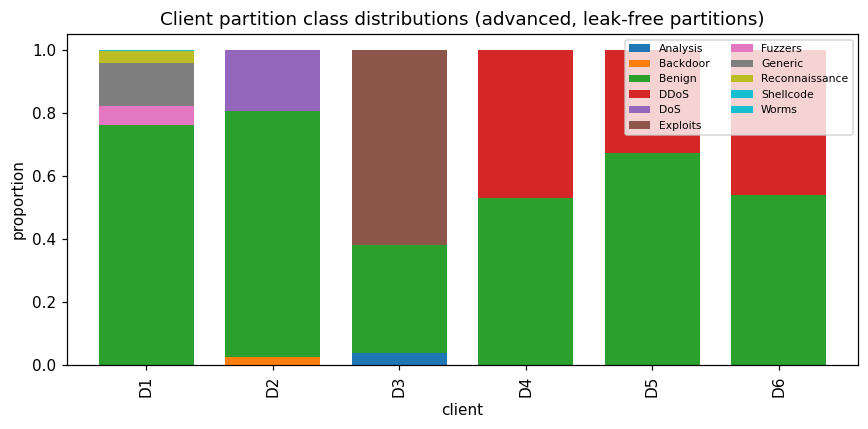

,D1,D2,D3,D4,D5,D6
attack_type,,,,,,
Analysis,0,0,1610,0,0,0
Backdoor,0,473,0,0,0,0
Benign,13973,14184,14184,15442,15676,15676
DDoS,0,0,0,13632,7624,13335
DoS,0,3520,0,0,0,0
Exploits,0,0,25869,0,0,0
Fuzzers,1100,0,0,0,0,0
Generic,2479,0,0,0,0,0
Reconnaissance,676,0,0,0,0,0


,model,params,size_MB,MACs_per_inference,MFLOPs_per_inference
0,AdvFcNN,12737,0.0509,12064,0.0241


In [23]:
plot_partition_distribution(parts_adv, 'Client partition class distributions (advanced, leak-free partitions)')

_m = make_adv_model()
model_facts = {'AdvFcNN': dict(Model='AdvFcNN', params=sum(q.numel() for q in _m.parameters()),
                               size_MB=4 * sum(q.numel() for q in _m.parameters()) / 1e6, macs=macs_estimate(_m, len(FEATURES) + 1))}
mf = model_facts['AdvFcNN']
display(pd.DataFrame([dict(model='AdvFcNN', params=mf['params'], size_MB=round(mf['size_MB'], 4), MACs_per_inference=mf['macs'],
                           MFLOPs_per_inference=round(2 * mf['macs'] / 1e6, 4))]))

## Advanced federated loop (FedProx + robust aggregation + DP + INT8)

In [24]:
def run_advanced_fl(parts, val_df, eval_df, strategy='FedAvg', robust=None, rounds=20, local_epochs=2, lr=2e-3, batch_size=256,
                    mu=0.01, clip_norm=None, dp_sigma=0.01, quantize=True, byzantine=(), byz_scale=5.0, max_rows=20000,
                    seed=SEED, domain_flag=True, verbose=True, tag='', min_clients=None):
    set_seed(seed)
    gm = AdvFcNN(input_dim=len(FEATURES) + (1 if domain_flag else 0))
    server = AdaptiveServerOptimizerV2(sum(p.numel() for p in gm.parameters()), strategy=strategy, robust=robust)
    dp = LocalDPEngine(clip_norm, dp_sigma, seed=seed) if clip_norm else None
    quant = Int8StochasticQuantizer(seg_sizes(gm), seed=seed) if quantize else None
    up_bytes = fp32_equiv = 0; history = []
    n_params = sum(p.numel() for p in gm.parameters()); down_bytes = 0; eval_history = []; y_eval = eval_df['label'].values
    for r in range(1, rounds + 1):
        t_round = time.time(); t_clients = 0.0
        if min_clients is None: chosen = CLIENT_IDS
        else:
            pick = np.random.RandomState(seed * 1000 + r).choice(len(CLIENT_IDS), size=min_clients, replace=False)
            chosen = [CLIENT_IDS[i] for i in sorted(pick)]
        g_flat = flat_of(gm); deltas, sizes = [], []
        for cid in chosen:
            df = parts[cid].sample(n=min(max_rows, len(parts[cid])), replace=False, random_state=seed + r)
            t_c = time.time()
            d = client_update_v2(copy.deepcopy(gm), g_flat, df, local_epochs, lr, batch_size, mu, domain_flag).numpy()
            t_clients += time.time() - t_c
            fp32_equiv += 4 * d.size
            if cid in byzantine:
                sent = -byz_scale * d; up_bytes += 4 * d.size
            else:
                if dp is not None: d = dp.privatize(d)
                if quant is not None:
                    payload = quant.quantize(d); up_bytes += quant.nbytes(payload); d = quant.dequantize(payload)
                else: up_bytes += 4 * d.size
                sent = d
            deltas.append(torch.tensor(sent, dtype=torch.float32)); sizes.append(len(df))
        load_flat(gm, server.aggregate(gm, deltas, sizes))
        down_bytes += 4 * n_params * len(chosen)                      # FP32 global-model broadcast
        p_val = predict_proba_adv(gm, val_df, domain_flag)
        history.append(dict(round=r, **{k: round(v, 4) for k, v in binary_metrics(val_df['label'].values, p_val >= 0.5).items()}))
        p_ev_r = predict_proba_adv(gm, eval_df, domain_flag)
        eval_history.append(dict(round=r, **{k: round(float(v), 4) for k, v in bin_suite(y_eval, p_ev_r).items()},
                                 round_train_s=round(t_clients, 3), round_s=round(time.time() - t_round, 3),
                                 cum_MB=round((up_bytes + down_bytes) / 1e6, 4)))
        if verbose and (r % 4 == 0 or r == rounds): print(f'  [{tag}] round {r:>2} | val acc {history[-1]["acc"]:.4f} | val F1 {history[-1]["f1"]:.4f}')
    p_ev = predict_proba_adv(gm, eval_df, domain_flag)
    res = dict(model=gm, history=history, uplink_bytes=up_bytes, uplink_fp32_equiv=fp32_equiv,
               eps=(dp.epsilon(1e-5, rounds) if dp else None), domain_flag=domain_flag)
    res['eval'] = binary_metrics(eval_df['label'].values, p_ev >= 0.5, p_ev)
    n_active = len(CLIENT_IDS) if min_clients is None else min_clients
    res.update(eval_history=pd.DataFrame(eval_history), model_type='AdvFcNN', strategy=strategy, n_params=n_params,
               model_MB=4 * n_params / 1e6, down_bytes=down_bytes, final_prob=p_ev, seed=seed, local_epochs=local_epochs,
               rounds=rounds, min_clients=min_clients,
               bytes_per_round=(up_bytes + down_bytes) / rounds)       # INT8 uplink (actual) + FP32 downlink, all active clients
    res['uplink_MB_per_round'] = up_bytes / rounds / 1e6
    res['uplink_fp32_MB_per_round'] = 4 * n_params * n_active / 1e6
    res['downlink_MB_per_round'] = 4 * n_params * n_active / 1e6
    return res

In [25]:
t0 = time.time()
adv_main = run_advanced_fl(parts_adv, val_fuse, df_eval_clean, strategy='FedAvg', mu=0.01, tag='adv FedAvg+FedProx+INT8')
print('ADVANCED classifier (FedAvg+FedProx+INT8) eval:', {k: round(v, 4) for k, v in adv_main['eval'].items()}, f'({time.time()-t0:.0f}s)')
print('uplink: %.1f KB sent vs %.1f KB if FP32  ->  %.1f%% saving' % (adv_main['uplink_bytes'] / 1e3, adv_main['uplink_fp32_equiv'] / 1e3,
      100 * (1 - adv_main['uplink_bytes'] / adv_main['uplink_fp32_equiv'])))

  [adv FedAvg+FedProx+INT8] round  4 | val acc 0.9084 | val F1 0.9215
  [adv FedAvg+FedProx+INT8] round  8 | val acc 0.9044 | val F1 0.9171
  [adv FedAvg+FedProx+INT8] round 12 | val acc 0.9133 | val F1 0.9252
  [adv FedAvg+FedProx+INT8] round 16 | val acc 0.9162 | val F1 0.9276
  [adv FedAvg+FedProx+INT8] round 20 | val acc 0.9192 | val F1 0.9304
ADVANCED classifier (FedAvg+FedProx+INT8) eval: {'acc': 0.9191, 'f1': 0.9303, 'prec': 0.9919, 'rec': 0.8759, 'auc': np.float64(0.9931)} (111s)
uplink: 1535.2 KB sent vs 6113.8 KB if FP32  ->  74.9% saving


## Experiment grid: FedProx client update × 5 server aggregation rules × N_RUNS

In [ ]:
ADV_STRATEGIES = ('FedAvg', 'TrimmedMean', 'GeoMedian', 'FedAdam', 'FedYogi')
t0 = time.time()
grid_results = []
for strategy in ADV_STRATEGIES:
    for run in range(1, N_RUNS + 1):
        res = run_advanced_fl(parts_adv, val_fuse, df_eval_clean, strategy=strategy, mu=FEDPROX_MU, rounds=ROUNDS,
                              local_epochs=LOCAL_EPOCHS, seed=SEED + run, verbose=(run == 1), tag=f'adv/{strategy}/run{run}')
        h = res['eval_history'].assign(model='AdvFcNN', strategy=strategy, run=run)
        grid_results.append((res, h))
        print(f"== AdvFcNN/{strategy} run {run}/{N_RUNS} done | final kappa {float(h.iloc[-1]['kappa']):.4f} | {time.time() - t0:.0f}s elapsed")

fl_long, grid_meta, final, LAST_ROUND = build_grid_tables(grid_results)
display(grid_meta.groupby(['model', 'strategy']).mean(numeric_only=True).drop(columns='run').round(3))

  [adv/FedAvg/run1] round  4 | val acc 0.8519 | val F1 0.8716
  [adv/FedAvg/run1] round  8 | val acc 0.9019 | val F1 0.9160
  [adv/FedAvg/run1] round 12 | val acc 0.9097 | val F1 0.9226
  [adv/FedAvg/run1] round 16 | val acc 0.8668 | val F1 0.8800
  [adv/FedAvg/run1] round 20 | val acc 0.9178 | val F1 0.9294
== AdvFcNN/FedAvg run 1/3 done | final kappa 0.8309 | 114s elapsed
== AdvFcNN/FedAvg run 2/3 done | final kappa 0.8240 | 226s elapsed
== AdvFcNN/FedAvg run 3/3 done | final kappa 0.8373 | 339s elapsed
  [adv/TrimmedMean/run1] round  4 | val acc 0.8338 | val F1 0.8577
  [adv/TrimmedMean/run1] round  8 | val acc 0.8796 | val F1 0.8938
  [adv/TrimmedMean/run1] round 12 | val acc 0.8939 | val F1 0.9070
  [adv/TrimmedMean/run1] round 16 | val acc 0.9036 | val F1 0.9158
  [adv/TrimmedMean/run1] round 20 | val acc 0.8646 | val F1 0.8775
== AdvFcNN/TrimmedMean run 1/3 done | final kappa 0.7336 | 454s elapsed
== AdvFcNN/TrimmedMean run 2/3 done | final kappa 0.8372 | 567s elapsed
== AdvFcNN

## Final-round classification metrics

Mean over runs at the final round, on the leak-free evaluation set. **Bold = best** per metric. Metrics: accuracy,
**balanced accuracy**, F1, precision, recall, **Cohen's Kappa**, **MCC**, **AUC** — the binary views of the GuardNet metric suite.

In [35]:
table2 = final.groupby(['model', 'strategy'])[METRIC_COLS].mean().round(4)
table2.columns = [PRETTY[c] for c in table2.columns]
show_best_bold(table2)
table2.to_csv(f'{PIPE}_table2_results.csv'); print(f'saved {PIPE}_table2_results.csv')

best_model, best_strategy = final.groupby(['model', 'strategy'])['kappa'].mean().idxmax()
print(f"best combination by Cohen's Kappa: {best_model} + {best_strategy}   (selection on the eval set, as in the GuardNet notebook; read the whole table, not only the winner)")

saved advanced_table2_results.csv
best combination by Cohen's Kappa: AdvFcNN + FedAvg   (selection on the eval set, as in the GuardNet notebook; read the whole table, not only the winner)


## Best-combination deep dive

ROC / precision–recall on the binary view, per-category detection (benign = specificity), the 2×2 confusion matrix, and the
per-round cost for the best aggregation strategy.

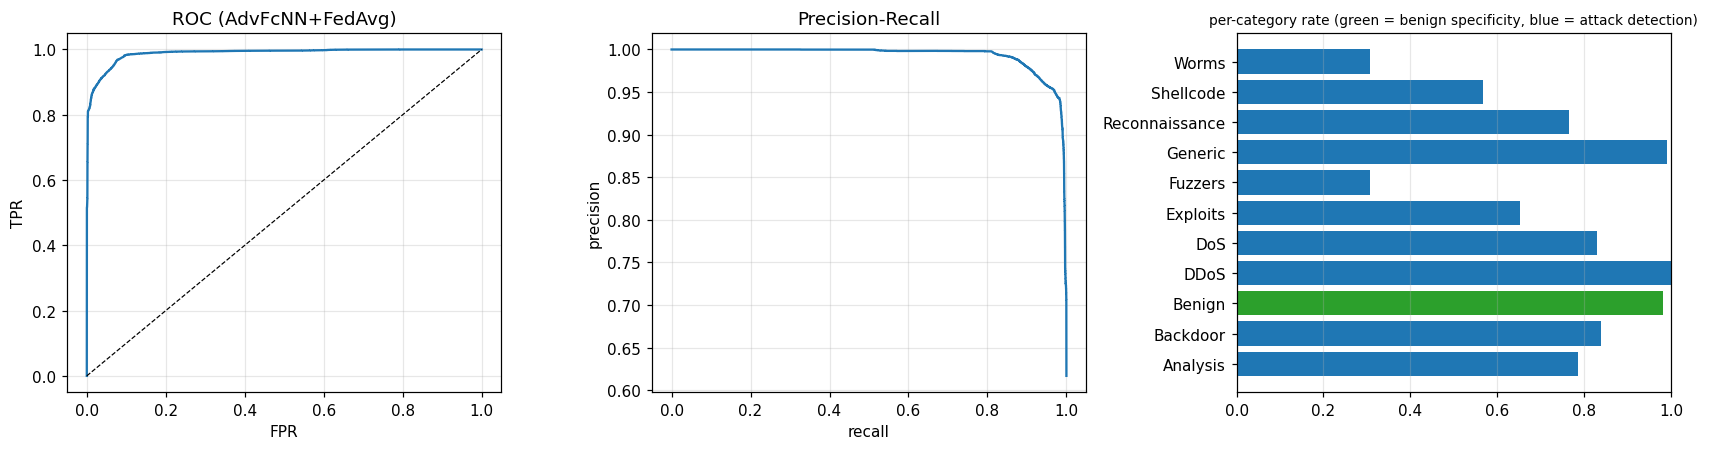

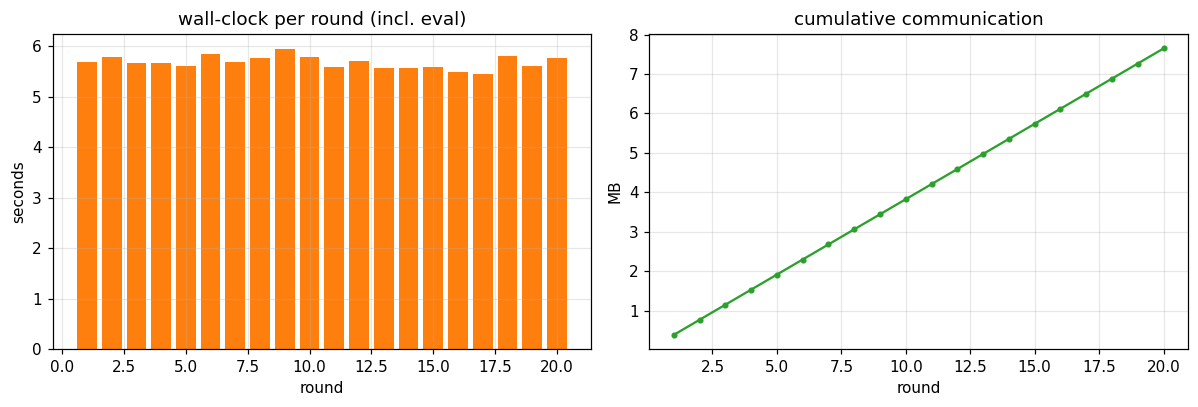

,category,n,rate
0,Analysis,200,0.7850
1,Backdoor,175,0.8400
2,Benign,15369,0.9828
3,DDoS,12803,0.9993
4,DoS,1226,0.8287
5,Exploits,3340,0.6518
6,Fuzzers,1819,0.3079
7,Generic,4000,0.9910
8,Reconnaissance,1049,0.7645
9,Shellcode,113,0.5664


,pred:Benign,pred:Attack
true:Benign,15105,264
true:Attack,3053,21685


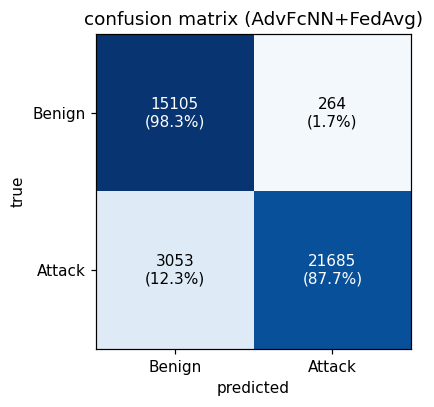

In [36]:
best_run = next(r for r, h in grid_results if r['strategy'] == best_strategy)
cat_best = plot_deep_dive(best_run, df_eval_clean, f'{best_model}+{best_strategy}')
display(cat_best.round(4))
plot_confusion(df_eval_clean, best_run['final_prob'], f'{best_model}+{best_strategy}')

## Complexity analysis 

,Model,Algorithm,Params,Size_MB,MACs,Time_per_round_s,MB_per_round,MB_per_round_if_FP32,Total_comm_MB,Final_Kappa
0,AdvFcNN,Centralized,12737,0.0509,12064,4.818,-,-,6.575,0.9153
1,AdvFcNN,FedAdam,12737,0.0509,12064,5.477,0.3824,0.6114,7.648,0.7430
2,AdvFcNN,FedAvg,12737,0.0509,12064,5.522,0.3824,0.6114,7.648,0.8307
3,AdvFcNN,FedYogi,12737,0.0509,12064,5.617,0.3824,0.6114,7.648,0.7348
4,AdvFcNN,GeoMedian,12737,0.0509,12064,5.415,0.3824,0.6114,7.648,0.7525
5,AdvFcNN,TrimmedMean,12737,0.0509,12064,5.540,0.3824,0.6114,7.648,0.7865


saved advanced_table1_complexity.csv


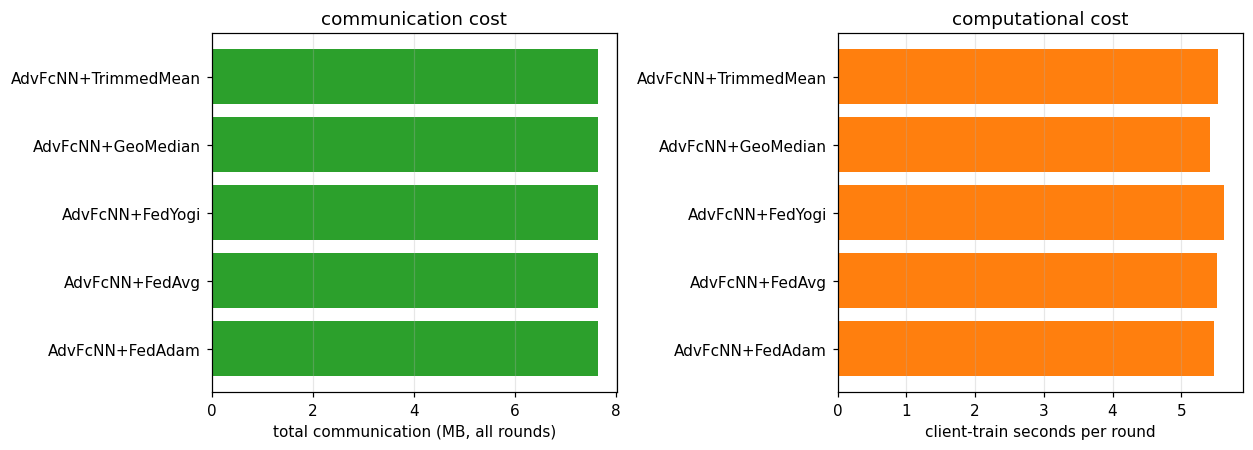

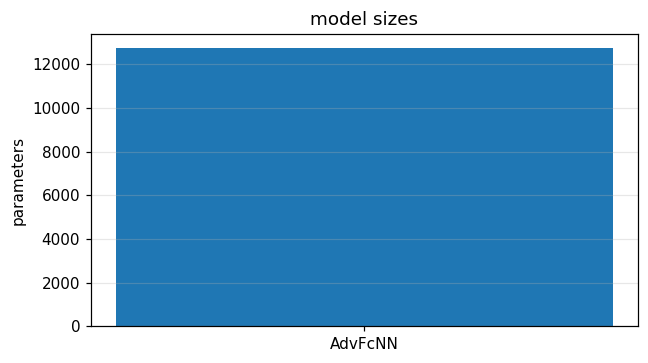

uplink per round: 0.0768 MB (INT8) vs 0.3057 MB (FP32)  ->  74.9% saving


,component,params,size_MB,MACs,MB_per_round,communicated
0,"AdvFcNN classifier (federated, INT8 uplink)",12737,0.0509,12064,0.3824,yes
1,"SpatialAE x1 per client (benign-only, local)",3559,0.0142,13104,0.0000,no (local templates)
2,"TemporalGuard GRU/LSTM (federated, FP32)",1073,0.0043,976,0.0515,"yes (10 guard rounds, native)"
3,IncrementalMemoryFilter x1 per client,4,0.0000,2,0.0000,"no (4 scalars: n, mean, var, k)"


In [37]:
mf = model_facts['AdvFcNN']; p = mf['params']
fp32_MB_round = 4 * p * len(CLIENT_IDS) * 2 / 1e6
sub = grid_meta.groupby('strategy').mean(numeric_only=True)
fin = final.groupby('strategy')['kappa'].mean()
rows, cent = [], None
if RUN_CENTRALIZED:
    cent = run_centralized_adv()
    rows.append(dict(Model='AdvFcNN', Algorithm='Centralized', Params=p, Size_MB=round(mf['size_MB'], 4), MACs=mf['macs'],
                     Time_per_round_s=round(cent['wall_s'] / ROUNDS, 3), MB_per_round='-', MB_per_round_if_FP32='-',
                     Total_comm_MB=round(cent['data_MB'] + cent['model_MB'], 3), Final_Kappa=round(float(cent['history'].iloc[-1]['kappa']), 4)))
for strategy, r in sub.iterrows():
    rows.append(dict(Model='AdvFcNN', Algorithm=strategy, Params=p, Size_MB=round(mf['size_MB'], 4), MACs=mf['macs'],
                     Time_per_round_s=round(r['avg_client_train_s'], 3), MB_per_round=round(r['MB_per_round'], 4),
                     MB_per_round_if_FP32=round(fp32_MB_round, 4), Total_comm_MB=round(r['MB_per_round'] * ROUNDS, 3),
                     Final_Kappa=round(float(fin[strategy]), 4)))
table1 = pd.DataFrame(rows)
display(table1)
table1.to_csv(f'{PIPE}_table1_complexity.csv', index=False); print(f'saved {PIPE}_table1_complexity.csv')
plot_complexity(table1[table1['Algorithm'] != 'Centralized'])
plot_model_sizes({'AdvFcNN': p})

up_int8 = float(np.mean([r['uplink_MB_per_round'] for r, h in grid_results if r['strategy'] == best_strategy]))
up_fp32 = float(np.mean([r['uplink_fp32_MB_per_round'] for r, h in grid_results if r['strategy'] == best_strategy]))
print(f'uplink per round: {up_int8:.4f} MB (INT8) vs {up_fp32:.4f} MB (FP32)  ->  {100 * (1 - up_int8 / up_fp32):.1f}% saving')

gp = sum(q.numel() for q in guard.parameters()); mult = 3 if isinstance(guard.rnn, nn.GRU) else 4
guard_macs_step = mult * (guard.rnn.input_size * guard.rnn.hidden_size + guard.rnn.hidden_size ** 2) + guard.rnn.hidden_size
ae_p = sum(q.numel() for q in ae_bank['D1'].parameters())
components = [
    dict(component='AdvFcNN classifier (federated, INT8 uplink)', params=p, size_MB=round(4 * p / 1e6, 4), MACs=mf['macs'],
         MB_per_round=round(up_int8 + 4 * p * len(CLIENT_IDS) / 1e6, 4), communicated='yes'),
    dict(component='SpatialAE x1 per client (benign-only, local)', params=ae_p, size_MB=round(4 * ae_p / 1e6, 4),
         MACs=macs_estimate(ae_bank['D1'], len(FEATURES)), MB_per_round=0.0, communicated='no (local templates)'),
    dict(component='TemporalGuard GRU/LSTM (federated, FP32)', params=gp, size_MB=round(4 * gp / 1e6, 4), MACs=guard_macs_step,
         MB_per_round=round(4 * gp * len(CLIENT_IDS) * 2 / 1e6, 4), communicated='yes (10 guard rounds, native)'),
    dict(component='IncrementalMemoryFilter x1 per client', params=4, size_MB=0.0, MACs=2, MB_per_round=0.0, communicated='no (4 scalars: n, mean, var, k)')]
comp_table = pd.DataFrame(components)
display(comp_table)
adv_params, adv_macs, adv_size_MB = p, mf['macs'], mf['size_MB']

## Per-round convergence 

Mean over runs per round with a ±1 standard-deviation band: accuracy, balanced accuracy and Cohen's Kappa, one line per
aggregation strategy.

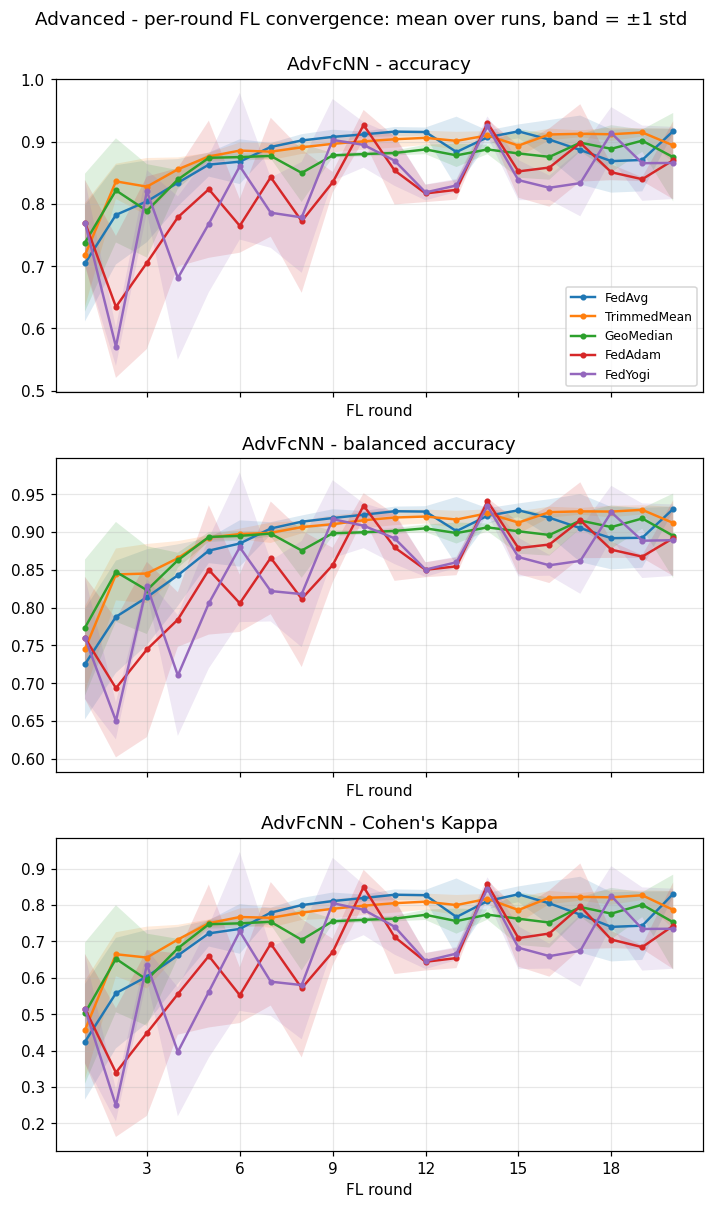

In [38]:
plot_convergence(fl_long, f'{PIPE}_convergence.png', 'Advanced - per-round FL convergence: mean over runs, band = ±1 std')

## Asynchronous FL 

async k=2 run 1 done | final acc 0.7901
async k=2 run 2 done | final acc 0.9092
async k=3 run 1 done | final acc 0.7383
async k=3 run 2 done | final acc 0.9119
async k=4 run 1 done | final acc 0.8121
async k=4 run 2 done | final acc 0.9264
async k=5 run 1 done | final acc 0.8216
async k=5 run 2 done | final acc 0.9077
async k=6 run 1 done | final acc 0.8176
async k=6 run 2 done | final acc 0.9184


,acc,bal_acc,f1,kappa
min_clients,,,,
2,0.8496,0.8754,0.8588,0.7056
3,0.8251,0.8532,0.8290,0.6634
4,0.8692,0.8886,0.8802,0.7410
5,0.8646,0.8872,0.8763,0.7318
6,0.8680,0.8908,0.8786,0.7392


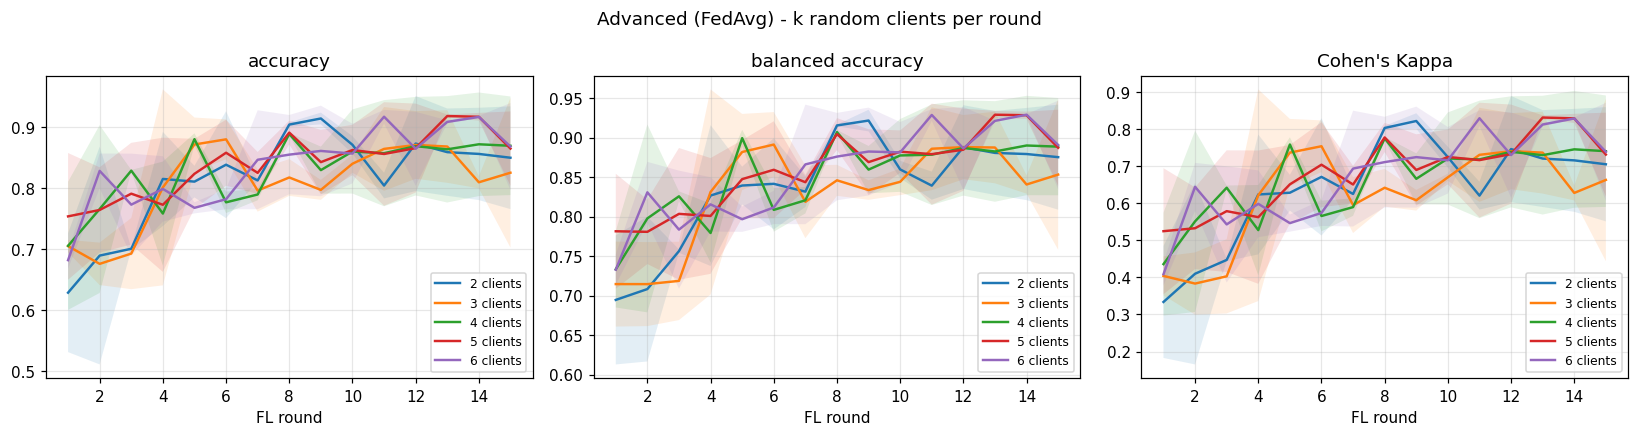

In [39]:
async_final = None
if RUN_ASYNC:
    async_rows = []
    for k in range(2, len(CLIENT_IDS) + 1):
        for run in range(1, N_ASYNC_RUNS + 1):
            res = run_advanced_fl(parts_adv, val_fuse, df_eval_clean, strategy=best_strategy, mu=FEDPROX_MU, rounds=ASYNC_ROUNDS,
                                  local_epochs=LOCAL_EPOCHS, seed=SEED + 200 + run, verbose=False, min_clients=k)
            async_rows.append(res['eval_history'].assign(min_clients=k, run=run))
            print(f'async k={k} run {run} done | final acc {float(res["eval_history"].iloc[-1]["acc"]):.4f}')
    async_long = pd.concat(async_rows, ignore_index=True)
    async_final = async_long[async_long['round'] == ASYNC_ROUNDS].groupby('min_clients')[['acc', 'bal_acc', 'f1', 'kappa']].mean().round(4)
    display(async_final)
    plot_async(async_long, f'{PIPE}_async.png', f'Advanced ({best_strategy}) - k random clients per round')

## Epoch-budget experiments: 5 vs 10 local epochs

AdvFcNN/FedAvg E= 5 | acc 0.8870 | kappa 0.7692 (136s elapsed)
AdvFcNN/FedAvg E=10 | acc 0.8234 | kappa 0.6540 (401s elapsed)
AdvFcNN/TrimmedMean E= 5 | acc 0.9012 | kappa 0.7988 (540s elapsed)
AdvFcNN/TrimmedMean E=10 | acc 0.8574 | kappa 0.7140 (806s elapsed)
AdvFcNN/GeoMedian E= 5 | acc 0.8815 | kappa 0.7614 (940s elapsed)
AdvFcNN/GeoMedian E=10 | acc 0.8780 | kappa 0.7547 (1207s elapsed)
AdvFcNN/FedAdam E= 5 | acc 0.8800 | kappa 0.7595 (1340s elapsed)
AdvFcNN/FedAdam E=10 | acc 0.8491 | kappa 0.6991 (1606s elapsed)
AdvFcNN/FedYogi E= 5 | acc 0.8188 | kappa 0.6476 (1740s elapsed)
AdvFcNN/FedYogi E=10 | acc 0.8352 | kappa 0.6766 (2006s elapsed)


,model,strategy,local_epochs,acc,bal_acc,f1,kappa,avg_round_s,MB_per_round
0,AdvFcNN,FedAvg,5,0.8870,0.8984,0.9027,0.7692,13.62,0.3824
1,AdvFcNN,FedAvg,10,0.8234,0.8531,0.8352,0.6540,26.46,0.3824
2,AdvFcNN,TrimmedMean,5,0.9012,0.9151,0.9144,0.7988,13.87,0.3824
3,AdvFcNN,TrimmedMean,10,0.8574,0.8766,0.8730,0.7140,26.67,0.3824
4,AdvFcNN,GeoMedian,5,0.8815,0.8999,0.8953,0.7614,13.37,0.3824
5,AdvFcNN,GeoMedian,10,0.8780,0.8969,0.8919,0.7547,26.66,0.3824
6,AdvFcNN,FedAdam,5,0.8800,0.9008,0.8930,0.7595,13.31,0.3824
7,AdvFcNN,FedAdam,10,0.8491,0.8709,0.8641,0.6991,26.62,0.3824
8,AdvFcNN,FedYogi,5,0.8188,0.8522,0.8284,0.6476,13.41,0.3824
9,AdvFcNN,FedYogi,10,0.8352,0.8647,0.8468,0.6766,26.55,0.3824


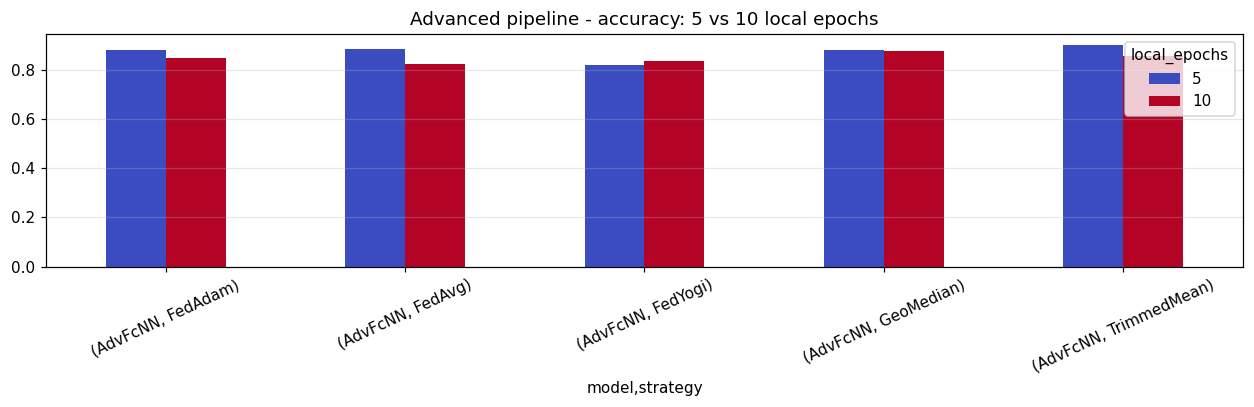

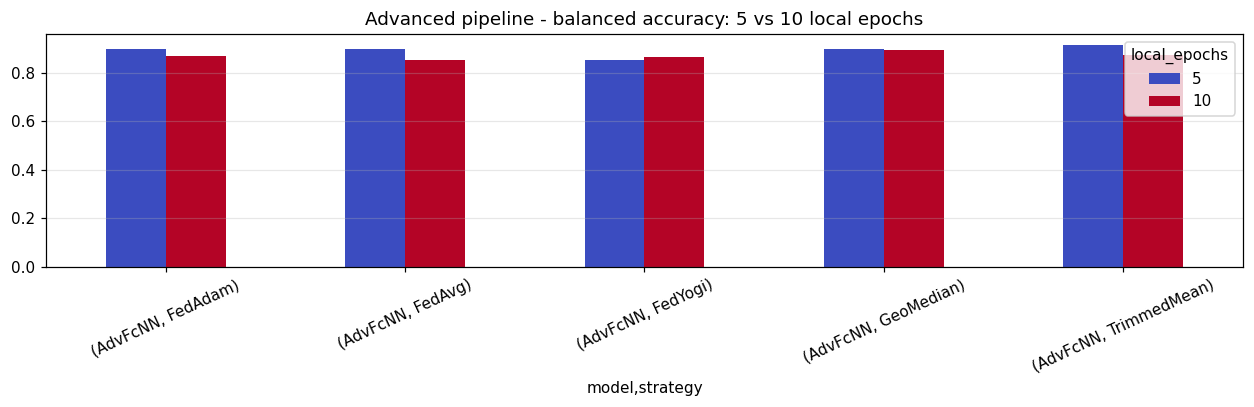

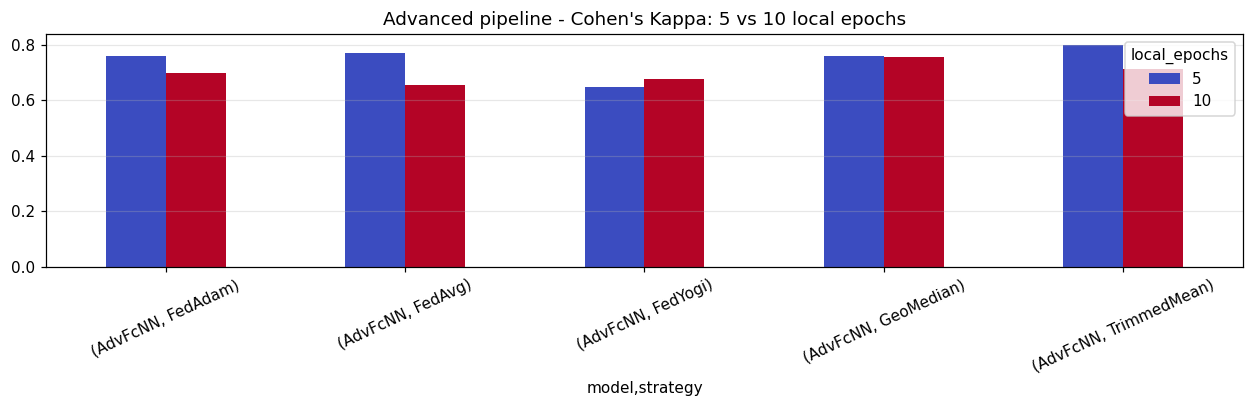

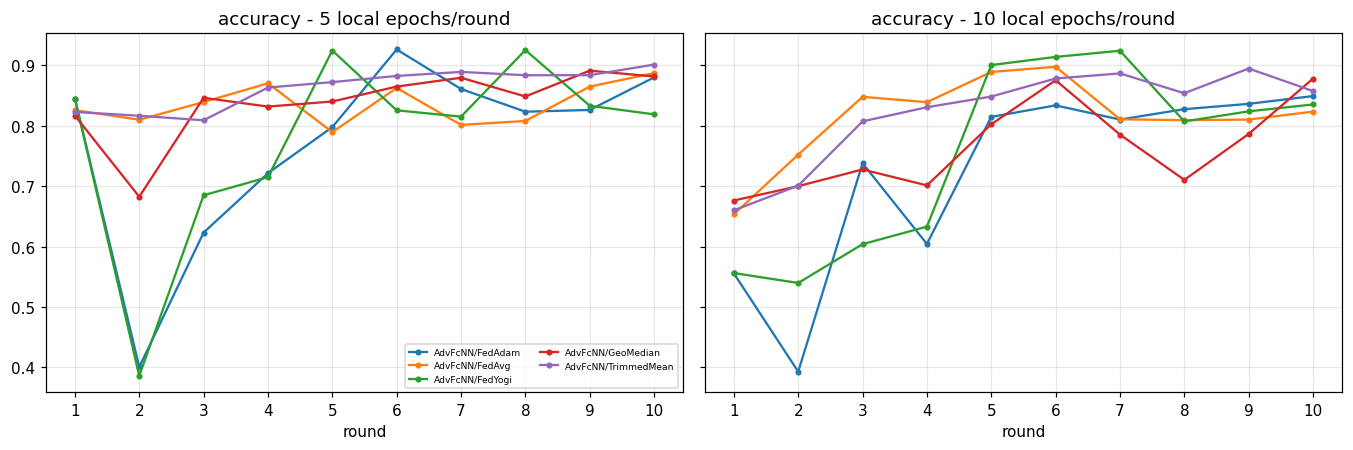

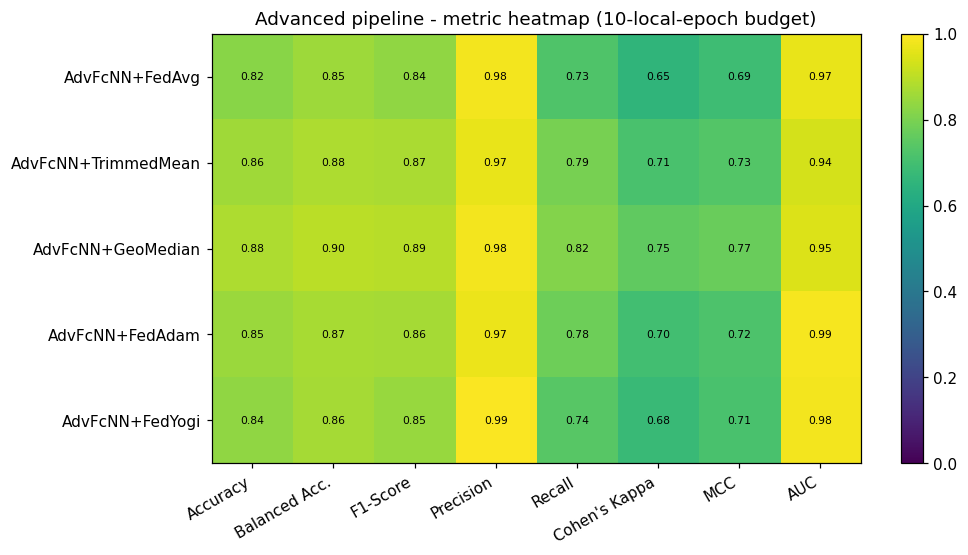

In [41]:
paper_epoch_rows, paper_epoch_frames, paper_epoch = [], [], None
if RUN_EPOCH_SWEEP:
    combos = list(ADV_STRATEGIES) if EPOCH_SWEEP_COMBOS == 'all' else [best_strategy]
    t0 = time.time()
    for st in combos:
        for ep in EPOCH_BUDGETS:
            res = run_advanced_fl(parts_adv, val_fuse, df_eval_clean, strategy=st, mu=FEDPROX_MU, rounds=EPOCH_SWEEP_ROUNDS,
                                  local_epochs=ep, seed=SEED + 1, verbose=False)
            h = res['eval_history']; last = h.iloc[-1]
            paper_epoch_frames.append(h.assign(model='AdvFcNN', strategy=st, local_epochs=ep))
            paper_epoch_rows.append(dict(model='AdvFcNN', strategy=st, local_epochs=ep, **{k: float(last[k]) for k in METRIC_COLS},
                                         avg_round_s=round(float(h['round_s'].mean()), 2), MB_per_round=round(res['bytes_per_round'] / 1e6, 4)))
            print(f"AdvFcNN/{st} E={ep:>2} | acc {last['acc']:.4f} | kappa {last['kappa']:.4f} ({time.time() - t0:.0f}s elapsed)")
    paper_epoch = pd.DataFrame(paper_epoch_rows)
    paper_epoch_hist = pd.concat(paper_epoch_frames, ignore_index=True)
    display(paper_epoch[['model', 'strategy', 'local_epochs', 'acc', 'bal_acc', 'f1', 'kappa', 'avg_round_s', 'MB_per_round']])
    plot_epoch_budget(paper_epoch, paper_epoch_hist, EPOCH_BUDGETS, 'Advanced pipeline')

In [43]:
bp = final[final['strategy'] == best_strategy][METRIC_COLS].mean()
best_hist = (fl_long[fl_long['strategy'] == best_strategy]
             .groupby('round')[METRIC_COLS + ['round_train_s', 'round_s', 'cum_MB']].mean().reset_index())
best_runs = [r for r, h in grid_results if r['strategy'] == best_strategy]
export = dict(
    pipeline='advanced (AdvFcNN + FedProx + robust/adaptive server + INT8 uplink; AE / memory filter / temporal guard alongside)',
    config=dict(rounds=ROUNDS, local_epochs=LOCAL_EPOCHS, fedprox_mu=FEDPROX_MU, lr=2e-3, batch_size=256, max_rows_per_client=20000,
                runs=N_RUNS, seeds=[SEED + r for r in range(1, N_RUNS + 1)], partition_scale=SCALE, eval_rows=len(df_eval_clean),
                eval_overlap_with_training='0 rows (asserted by assert_no_leak in build_clean_pipeline_data)',
                selection='best mean final-round Cohen Kappa on the eval set'),
    best_combo=best_strategy,
    final_metrics=dict(acc=bp['acc'], balanced_acc=bp['bal_acc'], kappa=bp['kappa'], f1=bp['f1'], prec=bp['prec'],
                       rec=bp['rec'], mcc=bp['mcc'], auc=bp['auc']),
    final_round_all_combos={f'AdvFcNN/{s}': row.to_dict() for s, row in final.groupby('strategy')[METRIC_COLS].mean().round(4).iterrows()},
    per_round=best_hist.to_dict(orient='records'),
    per_category=cat_best.to_dict(orient='records'),
    complexity=dict(classifier_params=adv_params, classifier_MB=round(adv_size_MB, 4),
                    total_MB_per_round=round(float(np.mean([r['bytes_per_round'] for r in best_runs])) / 1e6, 4),
                    uplink_MB_per_round_int8=round(up_int8, 4), uplink_MB_per_round_fp32_equiv=round(up_fp32, 4),
                    uplink_saving_pct=round(100 * (1 - up_int8 / up_fp32), 2),
                    downlink_MB_per_round_fp32=round(4 * adv_params * len(CLIENT_IDS) / 1e6, 4),
                    avg_round_time_s=round(float(np.mean([h['round_train_s'].mean() for r, h in grid_results if r['strategy'] == best_strategy])), 3),
                    MACs=adv_macs, components=comp_table.to_dict(orient='records'), per_combo=table1.to_dict(orient='records')),
    async_final=None if async_final is None else async_final.reset_index().to_dict(orient='records'),
    epoch_budgets=None if paper_epoch is None else dict(local_epochs=list(EPOCH_BUDGETS), sweep_rounds=EPOCH_SWEEP_ROUNDS, sweep=paper_epoch.to_dict(orient='records')))
save_json(export, 'advanced_pipeline_results.json')

saved advanced_pipeline_results.json


In [44]:
import os, glob
def _find_json(name):
    """Working dir first, then any attached /kaggle/input dataset / notebook output."""
    if os.path.exists(name): return name
    hits = glob.glob(os.path.join('/kaggle/input', '**', name), recursive=True)
    return hits[0] if hits else name

def _nan(x): return float('nan') if x is None else x
cols = {}
if os.path.exists(_find_json('baseline_pipeline_results.json')):
    js = json.load(open(_find_json('baseline_pipeline_results.json'))); fm = js['final_metrics']
    mdl = {'FcNN': 'FcNN', 'OneD_CNN': '1dCNN'}[js['best_combo'].split('+')[0]]
    cx = next(m for m in js['complexity']['models'] if m['Model'] == mdl)
    cols[f"Baseline ({js['best_combo']})"] = {
        'Binary Accuracy': fm['acc'], 'Binary Balanced Accuracy': fm['balanced_acc'], "Cohen's Kappa (binary)": fm['kappa'],
        'Binary F1': fm['f1'], 'Precision': fm['prec'], 'Recall': fm['rec'], 'MCC (binary)': fm['mcc'], 'AUC': fm['auc'],
        'Parameters': cx['Params'], 'Model size (MB)': cx['Size_MB'], 'MB per round': cx['Comm_MB_per_episode'],
        'Avg client-train s/round': cx['Avg_time_per_episode_s_5ep']}
if os.path.exists(_find_json('advanced_pipeline_results.json')):
    js = json.load(open(_find_json('advanced_pipeline_results.json'))); fm = js['final_metrics']; cx = js['complexity']
    cols[f"Advanced ({js['best_combo']})"] = {
        'Binary Accuracy': fm['acc'], 'Binary Balanced Accuracy': fm['balanced_acc'], "Cohen's Kappa (binary)": fm['kappa'],
        'Binary F1': fm['f1'], 'Precision': fm['prec'], 'Recall': fm['rec'], 'MCC (binary)': fm['mcc'], 'AUC': fm['auc'],
        'Parameters': cx['classifier_params'], 'Model size (MB)': cx['classifier_MB'], 'MB per round': cx['total_MB_per_round'],
        'Avg client-train s/round': cx['avg_round_time_s']}
if os.path.exists(_find_json('paper_pipeline_results.json')):
    js = json.load(open(_find_json('paper_pipeline_results.json'))); bc = js['best_combo']
    fm = js['final_round_all_combos'][f"{bc['model']}/{bc['strategy']}"]
    mdl = 'FcNN' if bc['model'] == 'fcnn' else '1dCNN'
    cx = next(r for r in js['complexity'] if r['Model'] == mdl and r['Algorithm'] == bc['strategy'])
    cols[f"Paper pipeline ({bc['model']}+{bc['strategy']})"] = {
        'Binary Accuracy': fm['bin_acc'], 'Binary Balanced Accuracy': fm['bin_bal_acc'], "Cohen's Kappa (binary)": fm['bin_kappa'],
        'Binary F1': fm['bin_f1'], 'Precision': fm['bin_precision'], 'Recall': fm['bin_recall'],
        'MCC (binary)': float('nan'),     # the paper export only stores the MULTI-class MCC -> not comparable, left blank
        'AUC': _nan(fm.get('bin_auc')),
        'Parameters': cx['Params'], 'Model size (MB)': cx['Size_MB'], 'MB per round': _nan(cx['MB_per_round']),
        'Avg client-train s/round': cx['Time_per_round_s']}
comp = pd.DataFrame(cols).astype(float).round(4)
display(comp)
missing = [n for n in ('baseline', 'advanced', 'paper') if not os.path.exists(_find_json(f'{n}_pipeline_results.json'))]
if missing: print('not found yet (run that notebook, then re-run this cell):', ', '.join(missing))
if len(cols) >= 2:
    q = ['Binary Accuracy', 'Binary Balanced Accuracy', "Cohen's Kappa (binary)", 'Binary F1', 'Precision', 'Recall', 'AUC']
    ax = comp.loc[q].plot(kind='bar', figsize=(11.5, 4.2), rot=20, width=0.8)
    ax.set_ylim(0, 1.02); ax.set_title('End-to-end comparison - detection quality (final round, eval set)'); ax.grid(alpha=0.3, axis='y')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
    for ax, (row, ttl) in zip(axes, (('Parameters', 'model parameters'), ('MB per round', 'communication per round (MB, up+down)'),
                                     ('Avg client-train s/round', 'client-train seconds per round'))):
        vals = comp.loc[row]; ax.bar(range(len(vals)), vals.values, color=['tab:gray', 'tab:red', 'tab:blue'][:len(vals)])
        ax.set_xticks(range(len(vals)), [c.split(' (')[0] for c in vals.index], rotation=15); ax.set_yscale('log')
        ax.set_title(ttl); ax.grid(alpha=0.3, axis='y')
    fig.suptitle('End-to-end comparison - complexity (log scale)'); fig.tight_layout(); plt.show()


,Advanced (FedAvg)
Binary Accuracy,0.9170
Binary Balanced Accuracy,0.9305
Cohen's Kappa (binary),0.8307
Binary F1,0.9285
Precision,0.9915
Recall,0.8730
MCC (binary),0.8403
AUC,0.9899
Parameters,12737.0000
Model size (MB),0.0509


not found yet (run that notebook, then re-run this cell): baseline, paper
